# 2-motor: rest-resistance

Measure the motor's terminal resistance at rest over the rotor's angle with the board's own current and terminal taps, and read the brush drop off the line through the stall laps, so the teardown and stage 3 have a number and its spread to compare against.

## Purpose

The terminal resistance of a brushed DC motor is the first number most later models lean on. The current a rail pushes into a locked rotor, the copper's temperature read as a change in resistance, the back-EMF taken out of a terminal reading under drive, and the share of a servo's heat that lands in the winding all start from it. The motor has no datasheet. Its registry entry in `oscnb/motors.py` carries only what can be counted, three slots, two brushes and a nine tooth pinion, so the resistance comes from here.

Two things make the number harder than one reading. The current reaches the winding through two brush contacts, and what the contacts add depends on where the rotor stopped, on which commutator segment sits under each brush and how it sits. So a reading belongs to the rotor's stop and not to the motor, and the first question is how wide the spread over the angle is and what shape it has. The second is that a brush contact does not behave like a resistor. Part of its drop stays about the same as the current changes, so a ratio of volts over amps carries that part as a resistance that grows as the current falls. A line of volts against amps through the locked rotor separates the two,

$$V = V_0 + R \, I$$

where $V$ is the terminal voltage, $I$ the current, $R$ the slope, the resistance, and $V_0$ the intercept, the brush drop.

The route here is the board's own. It drives 100 % duty into the locked rotor at three 1S rail levels and reads the current and the terminal voltage on the board's chains, which stage 1 graded against the meter. Nothing outside the board is in the reading, so the same route can run on an assembled servo later. The teardown at the end of this stage reads the copper with no brushes in the path, and the difference between the two is what the brushes own.

## Procedure

`capture.py` steps the rig's wrench bar through the twelve holes of its bolt circle, which hold the rotor by its pinion at angles 30 degrees apart, and prompts at each hole, so every lap belongs to a known rotor angle. The bar is clamped on the pinion and pinned into the plate, and nothing pushes or pulls along the shaft, since a shaft pressed past its end play rides the brushes wrong.

The motor's leads go on the board's motor connector, and the board comes up on the DPS. At each hole the script trims the rail to 3.3 V, 3.7 V and 4.2 V, the three 1S levels, and at each level runs one `osc-lab sweep`. A sweep is a half second torque-off baseline, 100 % duty for 300 ms in direction +1, a second of rest and 300 ms in direction -1. At 100 % the bridge holds one leg high and one low for the whole lap and nothing switches, so the chip's samples read DC quantities. The three levels keep the stall current under an amp, and a lap puts under a joule into the motor. After the three levels the script holds twenty seconds, the bench rule for a bare motor, and then asks for the next hole.

1. The motor in the rig with its two leads soldered to the tabs, the bar on the pinion at hole 0, pins in.
2. The leads on the board's motor connector. The board on the DPS with the adapter on its bus at 3 Mbps, running the experiment image, so the laps are open loop with only the raw current trip and the bus dead-man as protections. The DPS comes on before the board's leads go on, because its output comes up at its previous setting for a moment.
3. `capture.py`. At each prompt, pins out, the bar turned to the next hole, pins in.

The levels name the rail, VSYS. The dev board has a feed diode, so the DPS is trimmed over it until the board's own rail tap reads the level.

## Data

One folder under the capture, `stall`.

- `stall/laps.csv`: one row per hole and level. `hole`, `volts_set` the rail asked for, `dps_read` the DPS output that reached it, `vsys_read` the rail the board read at rest before the sweep, `t_start` and `t_end` the host time the sweep ran, `folder` the sweep's folder.
- `stall/hole-K/<V>V/sweep.csv` and `meta.json`, with V one of 3.3, 3.7 and 4.2: the baseline and the two directions at that hole and level, one row per control tick at 20 kHz. Segment 0 is the baseline, 1 is direction +1 and 2 is direction -1. `current_raw`, `vmotor_a`, `vmotor_b`, `vbus_raw` and `ntc_raw` are ADC counts, `duty_counts` the applied window in timer ticks. `vref_raw` is in the header but empty, the lap's telemetry chunk does not carry it. `tick` restarts at 0 in every segment, and a jump in it is a dropped row. Each segment is its own stream from the board and opens with a few rows before the drive starts.

### Setup

The motor, the board and the dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, laps, motors, results, tel
from oscnb.display import show

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"   # the house colors
MOTOR = motors.MOTORS[motors.DEFAULT]                                   # the motor, with its counted parts
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "rest-resistance" / "capture-1").resolve()
STALL = CAPTURE / "stall"                                               # the stall pass, the only pass of this capture
FS = BOARD.tick_hz                                                      # rows per second, the control rate
DEG_PER_HOLE = 30                                                       # the rig's bolt circle, twelve holes
COLOR = {3.3: MUTED, 3.7: BLUE, 4.2: ORANGE}                            # one color per rail level, the ungraded 3.3 V level in gray
DIR_COLOR = {1: BLUE, -1: ORANGE}                                       # one color per direction where the levels are pooled
MARK = {1: "o", -1: "^"}                                                # the direction as the marker shape, +1 filled, -1 open
print(MOTOR.key, "on", BOARD.key, "from", results.rel(CAPTURE))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes, a {MOTOR.pinion_teeth} tooth pinion; rows at {FS} Hz")

mg90-b on dev-v006-2A-D from telemetry/mg90-b__dev-v006-2A-D/rest-resistance/capture-1
the motor of MG90 clone b: 3 slots, 2 brushes, a 9 tooth pinion; rows at 20000 Hz


### Stage 1 values carried in

The current goes through the current-scale result and the terminal volts through the terminal-chain result. Both hold from the 3.7 V level up and report the 3.3 V level apart, since the board's 3.3 V regulator runs out of headroom on a 1S rail at that level and the converter's reference, VDD, falls with it. The back-EMF constant from bemf-coast is read for one check further down.

In [2]:
CS = results.read("1-board", "current-scale", pair=BOARD.key)           # counts per amp and the in-drive offset over the lap's own zero
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)          # counts per volt of tap difference and its offset
KE = results.read("2-motor", "bemf-coast", pair=MOTOR.key)["ke_v_s_per_rad"]["value"]   # the back-EMF constant, for the motion check
G_CPA, B_OFF = CS["counts_per_a"]["value"], CS["drive_offset_counts"]["value"]
K_CPV, C_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]
RAIL_GRADED_V = TC["rail_range_v"]["lo"] + 0.015                       # both results hold from the 3.7 V level up; the rail range starts at 3.685 V
TERM_3V3, CUR_3V3 = TC["terminal_error_3v3_pct"]["value"], CS["deviation_3v3_bare_pct"]["value"]
F_3V3 = (1 + TERM_3V3 / 100) / (1 + CUR_3V3 / 100)                     # what V/I reads over the truth at the 3.3 V level, on the bare load
print(f"current: counts over the lap's zero = {B_OFF:+.1f} + {G_CPA:.1f} x amps ({CS['counts_per_a']['lo']:.1f} to {CS['counts_per_a']['hi']:.1f}), "
      f"graded over {CS['amps_range']['lo']:.2f} to {CS['amps_range']['hi']:.2f} A from {RAIL_GRADED_V:.1f} V up")
print(f"terminals: tap difference = {C_OFF:+.1f} + {K_CPV:.2f} x volts ({TC['terminal_counts_per_v']['lo']:.2f} to {TC['terminal_counts_per_v']['hi']:.2f})")
print(f"at the 3.3 V level, not graded: terminal difference {TERM_3V3:+.1f} % over the meter, current {CUR_3V3:+.1f} % over the line, "
      f"VDD {TC['vdd_3v3_v']['value']:.3f} V at rest and {TC['vdd_3v3_under_lap_v']['value']:.3f} V under the lap; so V/I reads {(F_3V3 - 1) * 100:+.1f} % there")
print(f"back-EMF constant {KE * 1e3:.4f} mV s/rad from bemf-coast")

current: counts over the lap's zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A from 3.7 V up
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
at the 3.3 V level, not graded: terminal difference +12.6 % over the meter, current +8.4 % over the line, VDD 3.120 V at rest and 3.006 V under the lap; so V/I reads +3.9 % there
back-EMF constant 1.1684 mV s/rad from bemf-coast


A count over the lap's own zero is 0.88 mA and a count of tap difference is 4.03 mV. At the 3.3 V level stage 1 found the terminal difference reading 12.6 % over the meter and the current 8.4 % over its line on the bare load. Most of both is VDD under the lap, about 3.0 V where the conversion assumes 3.3 V, and that part is the same on both chains and cancels in a ratio of volts over amps. The rest does not cancel. Taken together the two numbers say V/I at that level reads about 3.9 % over the truth on the bare load at 0.56 A. Stage 1 also found the remainder differs between its two loads, so the factor is a guide at the motor's 0.7 A and not a correction. The lap rows carry no `vref_raw`, so VDD under these laps is not known. The 3.3 V level enters no number below, and is drawn apart where it appears.

### stall/laps.csv

Every sweep of the pass, and when it ran.

,hole,volts_set,dps_read,vsys_read,t_start,t_end,folder,trim_mv
0,0,3.300,3.550,3.292,1793221603.253,1793221607.144,hole-0/3.3V,-8.000
1,0,3.700,3.950,3.695,1793221611.095,1793221614.926,hole-0/3.7V,-5.000
2,0,4.200,4.450,4.209,1793221618.841,1793221622.590,hole-0/4.2V,9.000
3,1,3.300,3.550,3.298,1793221748.249,1793221752.125,hole-1/3.3V,-2.000
4,1,3.700,3.950,3.700,1793221756.120,1793221760.004,hole-1/3.7V,0.000
5,1,4.200,4.450,4.209,1793221763.922,1793221767.793,hole-1/4.2V,9.000
6,2,3.300,3.550,3.303,1793221936.032,1793221939.939,hole-2/3.3V,3.000
7,2,3.700,3.950,3.700,1793221943.968,1793221947.908,hole-2/3.7V,0.000
8,2,4.200,4.450,4.200,1793221951.834,1793221955.692,hole-2/4.2V,0.000
9,3,3.300,3.550,3.281,1793222078.592,1793222082.452,hole-3/3.3V,-19.000


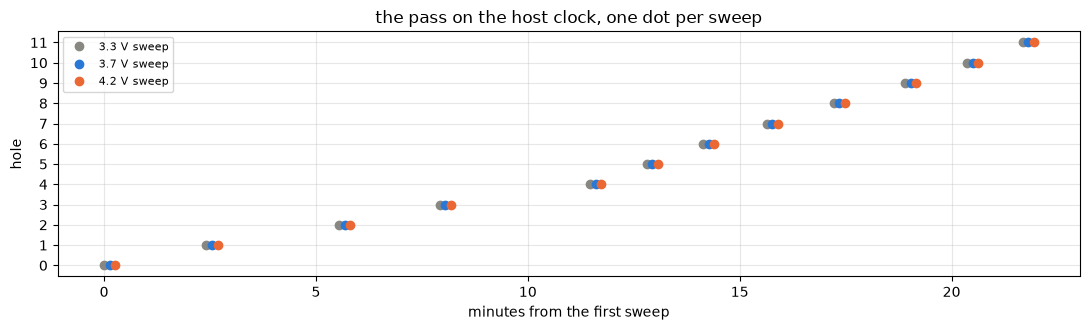

36 sweeps over 22.0 minutes; the rail landed within 19 mV of each level
seconds from one hole's last sweep to the next hole's first: {1: 126, 2: 168, 3: 123, 4: 194, 5: 60, 6: 60, 7: 71, 8: 75, 9: 82, 10: 69, 11: 59}
the three sweeps of a hole start 7.7 to 7.9 s apart and each takes 3.7 to 4.1 s on the host


In [3]:
lapdf = pd.read_csv(STALL / "laps.csv")
LEVELS = sorted(float(v) for v in lapdf["volts_set"].unique())
lapdf["trim_mv"] = (lapdf["vsys_read"] - lapdf["volts_set"]) * 1e3        # how far the trim landed from the level
show(lapdf, n=None)
T0 = lapdf["t_start"].min()                                              # the first sweep's start, the clock's zero
first, last = lapdf.groupby("hole")["t_start"].min(), lapdf.groupby("hole")["t_end"].max()
GAP_S = (first - last.shift(1)).rename("gap_s")                          # seconds from one hole's last sweep to the next hole's first
fig, ax = plt.subplots(figsize=(11, 3.4))
for v in LEVELS:
    g = lapdf[lapdf["volts_set"] == v]
    ax.plot((g["t_start"] - T0) / 60, g["hole"], "o", ms=6, color=COLOR[v], label=f"{v:g} V sweep")   # one dot per sweep
ax.set_xlabel("minutes from the first sweep"); ax.set_ylabel("hole"); ax.set_yticks(range(12))
ax.set_title("the pass on the host clock, one dot per sweep"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"{len(lapdf)} sweeps over {(lapdf['t_end'].max() - T0) / 60:.1f} minutes; the rail landed within {lapdf['trim_mv'].abs().max():.0f} mV of each level")
print("seconds from one hole's last sweep to the next hole's first:", {int(k): int(round(v)) for k, v in GAP_S.dropna().items()})
print(f"the three sweeps of a hole start {lapdf['t_start'].diff()[lapdf['hole'].diff() == 0].min():.1f} to "
      f"{lapdf['t_start'].diff()[lapdf['hole'].diff() == 0].max():.1f} s apart and each takes {(lapdf['t_end'] - lapdf['t_start']).min():.1f} to "
      f"{(lapdf['t_end'] - lapdf['t_start']).max():.1f} s on the host")

Twelve holes, three levels each, one dot per sweep on the host clock. The rail landed within 19 mV of its level every time. The three sweeps of a hole ran about 8 s apart. The rests between holes were not even. Holes 1 to 4 came two to three minutes after the hole before, while holes 5 to 11 came a minute or a little more after it, as the prompts went quicker. That changes how much heat the motor carries from hole to hole, and it comes back in the Results.

### One sweep, sweep.csv and meta.json

One sweep, hole 5 at the 4.2 V level, with the current channel and the two terminal taps over the baseline and the two directions, and the current's first 6 ms in direction +1.

hole 5 hole-5/4.2V | segments: {0: 10000, 1: 6000, 2: 6000} | schedule: ['100@300'] | dirs: [1, -1] | baseline ms: 500 | rest ms: 1000 | rows dropped: 0


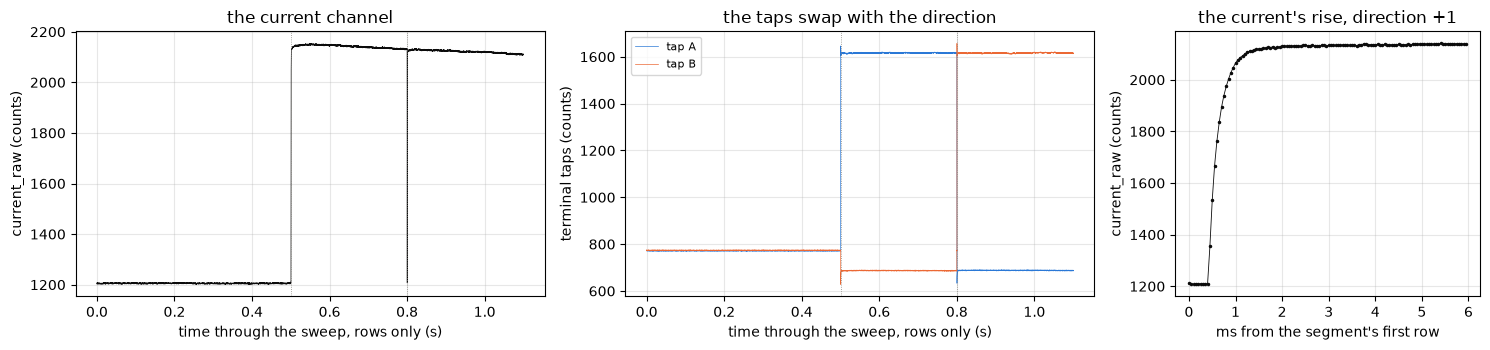

direction +1 opens with 9 rows before the drive; duty_counts under drive 1200 of 1200 ticks


In [4]:
SHOW = lapdf[(lapdf["hole"] == 5) & (lapdf["volts_set"] == 4.2)].iloc[0]
df, meta = tel.load(STALL / SHOW["folder"], BOARD)                     # checks the sense block against the board entry
print("hole", SHOW["hole"], SHOW["folder"], "| segments:", df["seg"].value_counts().sort_index().to_dict(), "| schedule:", meta["schedule"],
      "| dirs:", meta["dirs"], "| baseline ms:", meta["baseline_ms"], "| rest ms:", meta["rest_ms"], "| rows dropped:", meta["rows_dropped"])
ts = np.arange(len(df)) / FS                                            # time through the sweep as rows, since `tick` restarts at each segment
edges = np.flatnonzero(np.diff(df["seg"].to_numpy()) != 0) + 1
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [2, 2, 1.3]})
ax[0].plot(ts, df["current_raw"], lw=0.5, color=INK); ax[0].set_ylabel("current_raw (counts)"); ax[0].set_title("the current channel")
ax[1].plot(ts, df["vmotor_a"], lw=0.5, color=BLUE, label="tap A"); ax[1].plot(ts, df["vmotor_b"], lw=0.5, color=ORANGE, label="tap B")
ax[1].set_ylabel("terminal taps (counts)"); ax[1].set_title("the taps swap with the direction"); ax[1].legend(fontsize=8)
for a in ax[:2]:
    for e in edges:
        a.axvline(e / FS, color=MUTED, lw=0.6, ls=":")                 # segment edges, where the streams meet
    a.set_xlabel("time through the sweep, rows only (s)"); a.grid(alpha=0.3)
g = df[df["seg"] == 1].iloc[:120]                                        # the first 6 ms of direction +1
ax[2].plot(np.arange(len(g)) / FS * 1e3, g["current_raw"], ".-", ms=3, lw=0.6, color=INK)
ax[2].set_xlabel("ms from the segment's first row"); ax[2].set_ylabel("current_raw (counts)"); ax[2].set_title("the current's rise, direction +1"); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
on = int(np.flatnonzero(df[df["seg"] == 1]["duty_counts"].to_numpy() != 0)[0])
print(f"direction +1 opens with {on} rows before the drive; duty_counts under drive {sorted(df[df['seg'] > 0]['duty_counts'].abs().unique().tolist())[-1]} of {meta['pwm_period_ticks']} ticks")

Half a second at the zero, then 300 ms each way. The second of rest between the two directions is not recorded, so the two streams sit end to end. The current channel reads the same current in both directions, since the shunt sits in the bridge's common return, and the taps swap. The current falls slowly through both laps of this sweep, by 1 to 2 %, which is the copper warming, and the next section looks at it closely. On the right, the stream opens with 9 rows before the drive starts, and the current then rises to within a few counts of its settled value in about 1.5 ms, which is the winding's inductance against its resistance.

## Raw traces

Every lap's terminal volts over amps, $V/I$, through the lap, smoothed over 10 ms, one panel per level. Direction +1 in blue, direction -1 in orange, hole 0 in black. The thing to see is the shape inside a lap, and where the directions and the holes sit against each other.

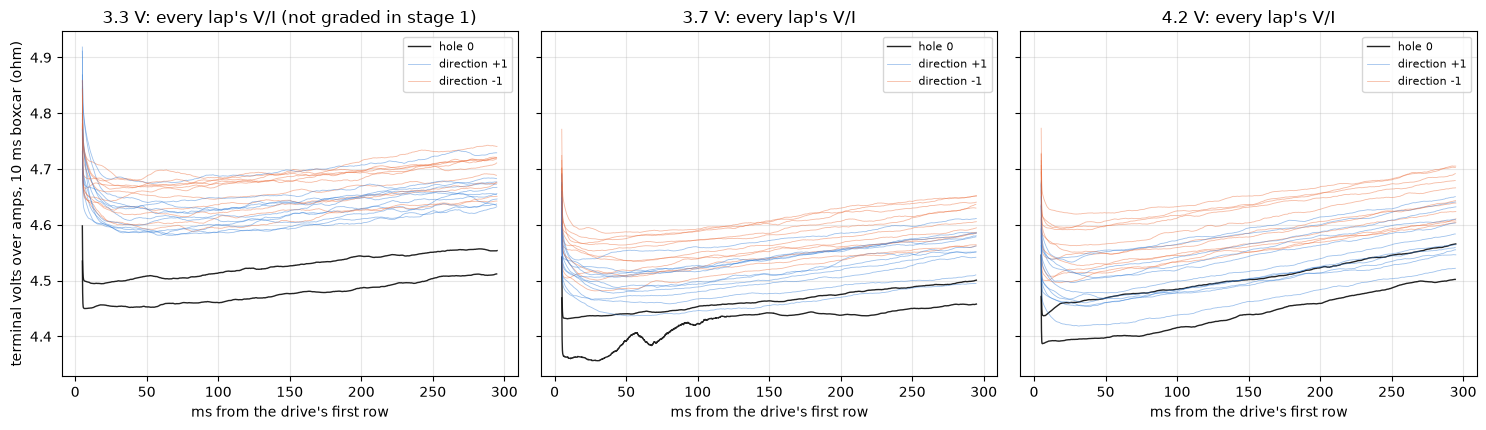

missing rows over all sweeps: 0


In [5]:
def lap_rows(L):
    # every direction of one sweep as arrays from its first driven row: time, amps, volts, and the lap's own zero
    df, meta = tel.load(STALL / L["folder"], BOARD)
    zero = float(tel.baseline(df)["current_raw"].median())              # the current channel's torque-off zero, the second half of the rest
    out = []
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        d = int(g["dir"].iloc[0])
        on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])   # a segment's stream opens with a few rows before the drive
        g = g.iloc[on:]
        amps = (g["current_raw"].to_numpy(float) - zero - B_OFF) / G_CPA  # the current-scale line inverted
        volts = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - C_OFF) / K_CPV   # the terminal-chain line inverted, signed by direction
        out.append({"dir": d, "seg": int(seg), "on": on, "t": np.arange(len(g)) / FS, "amps": amps, "volts": volts,
                    "zero": zero, "missing": int(tel.gaps(df).sum()), "rest": tel.baseline(df)})
    return out


def boxcar(x, n=200):
    # the mean over n rows, 10 ms at 20 kHz, centered
    return np.convolve(x, np.ones(n) / n, mode="same")


LAPS_RAW = {(int(L["hole"]), float(L["volts_set"])): lap_rows(L) for _, L in lapdf.iterrows()}   # every lap, kept for the figures below
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for (k, v), pair in LAPS_RAW.items():
    a = ax[LEVELS.index(v)]
    for p in pair:
        r = boxcar(p["volts"]) / boxcar(p["amps"])                       # V/I over 10 ms, every row
        keep = slice(100, len(r) - 100)                                  # the boxcar's half-width trimmed at both ends
        color = INK if k == 0 else DIR_COLOR[p["dir"]]                   # hole 0 in black, the rest by direction
        a.plot(p["t"][keep] * 1e3, r[keep], lw=0.6 if k else 1.0, color=color, alpha=0.9 if k == 0 else 0.45,
               label=(f"direction {p['dir']:+d}" if k == 1 else ("hole 0" if p["dir"] == 1 else None)) if k in (0, 1) else None)
for a, v in zip(ax, LEVELS):
    a.set_title(f"{v:g} V: every lap's V/I" + (" (not graded in stage 1)" if v < RAIL_GRADED_V else "")); a.set_xlabel("ms from the drive's first row")
    a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_ylabel("terminal volts over amps, 10 ms boxcar (ohm)")
plt.tight_layout(); plt.show()
print("missing rows over all sweeps:", sum(p["missing"] for pair in LAPS_RAW.values() for p in pair[:1]))

Every lap has the same two-part shape. Over the first 30 to 50 ms $V/I$ falls by about a percent, and from there it rises along a straight line to the end of the lap. The rise is the copper warming under about 2 to 3 W. The early fall gets its own look in the Results.

Two other things show at every level. The direction -1 laps sit above the direction +1 laps at nearly every hole. And hole 0 is the lowest at every level, by more than the other holes spread. Its 3.3 V laps also have no early fall, and its 3.7 V +1 lap wobbles through its first 100 ms, so hole 0 differs from the others in shape as well as in level. The 3.3 V panel sits about 0.1 ohm over the other two, which is close to what the stage 1 factor above predicts for the chain at that level. No row is missing from any sweep.

## Method

### Conversions

The current over the lap's own torque-off zero goes through the current-scale line, counts $= b + G \, I$, so

$$I = \frac{n - n_0 - b}{G}$$

with $n$ the current channel, $n_0$ the median of the second half of the lap's own baseline, $G$ the counts per amp and $b$ the in-drive offset. The terminal volts go through the terminal-chain line the same way,

$$V = \frac{d \, (n_A - n_B) - c}{k}$$

with $n_A$ and $n_B$ the two taps, $d$ the direction, $k$ the counts per volt and $c$ its offset. The taps sit at the board's connector, so $V$ is the voltage at the connector and the reading carries the connector's contact and the motor's two short leads on top of the motor.

### Reading a lap

Two things move $V/I$ inside a lap, the early fall and the warming. A reading over the early milliseconds reads the fall, and a mean over the lap reads half of the warming on top. Neither is the resistance of the motor as it was when the lap began.

So each lap is read as a straight line through $V/I$ against time, from 60 ms after the drive's first row to the end of the lap, extrapolated back to the drive's first row. The value there, $R_\mathrm{start}$, is the settled path's resistance with the copper at the temperature it had when the lap started. The line's slope is the warming rate. The current and the volts get a line of their own the same way, and their values at the start, $I_\mathrm{start}$ and $V_\mathrm{start}$, are the points of the line through the laps. The 60 ms is where the early fall has finished in every lap of the raw traces but hole 0's 3.7 V +1 lap, which wobbles to about 100 ms. The extrapolation reaches back 60 ms against a fit 240 ms long, and the warming is close to a straight line over the lap, which the line's residual in the table below checks.

This is a change from the plan made before the data came in, which read the plain mean of each direction from 2 ms in. On this data that mean reads about 1.1 % over the start, and the last 20 ms about 1.9 %. The plan also assumed the copper stays cold through a lap, and it warms by 1 to 3 % in 300 ms.

### Which laps carry the number

The terminal resistance at rest is read on the direction +1 laps at the 3.7 V and 4.2 V levels, per hole the mean of the two. Direction -1 runs a second after direction +1 and starts warm, which the Results show, so it is reported apart. The 3.3 V level is not graded in stage 1 and enters no number.

### The brush drop

The line $V = V_0 + R \, I$ is fitted per hole, through that hole's direction +1 laps at the start, $V_\mathrm{start}$ against $I_\mathrm{start}$. The same thing in the form the figures use is

$$\frac{V}{I} = R + \frac{V_0}{I}$$

so on a plot of $V/I$ against $1/I$ the slope is the brush drop and the intercept is the resistance. The plan fitted one line over every point of the pass. A line per hole keeps each hole's own contact in its own line, since the holes differ by a few percent and the current moves with them.

The levels give the line little room. Between 3.7 V and 4.2 V the current moves by about 0.1 A, from about 0.73 A to 0.84 A, so $1/I$ moves by about 0.17 per A. A difference of 0.1 % of $V/I$ between the two laps then moves $V_0$ by 27 mV. Anything that changes between the two laps of a hole by a tenth of a percent, a little heat carried from the laps before, shows up in $V_0$ at that size. The line is also run through all three levels, with the 3.3 V point as read and divided by the stage 1 factor, to show how much of the intercept rides on that level.

### The per-lap reduction

Every lap through the reading above, one row per lap.

In [6]:
FIT_FROM_S = 0.060        # the line through V/I starts here, past the early fall
EARLY_S = (0.002, 0.020)  # the early window, for comparison
LATE_S = 0.020            # the last 20 ms of the lap, for comparison

rows = []
for (k, v), pair in LAPS_RAW.items():
    for p in pair:
        t, i, u = p["t"], p["amps"], p["volts"]
        late = t >= FIT_FROM_S
        pr = np.polyfit(t[late], (u / i)[late], 1)                       # V/I against time over the fit window: slope and the value at the drive's start
        pi, pu = np.polyfit(t[late], i[late], 1), np.polyfit(t[late], u[late], 1)   # the current and the volts the same way, for the line
        early = (t >= EARLY_S[0]) & (t < EARLY_S[1])
        tail = t >= t[-1] - LATE_S
        res = boxcar((u / i)[late] - np.polyval(pr, t[late]))[100:-100]  # the line's residual over 10 ms
        rest = p["rest"]
        rows.append({"hole": k, "angle_deg": DEG_PER_HOLE * k, "level": v, "dir": p["dir"], "seg": p["seg"], "on_rows": p["on"],
                     "r_start": pr[1], "r_slope": pr[0], "r_end": np.polyval(pr, t[-1]),                     # ohm, ohm/s, ohm
                     "i_start": pi[1], "v_start": pu[1],                                                    # amps and volts at the start, by their own lines
                     "r_early": u[early].mean() / i[early].mean(), "r_tail": u[tail].mean() / i[tail].mean(),
                     "r_mean": u[t >= EARLY_S[0]].mean() / i[t >= EARLY_S[0]].mean(),                      # the plain settled mean, the skeleton's reading
                     "resid_mohm": np.sqrt(np.mean(res ** 2)) * 1e3, "watts": (u * i)[t >= EARLY_S[0]].mean(),
                     "joules": (u * i).sum() / FS, "lap_s": t[-1],
                     "board_c": float(BOARD.ntc_c_beta(rest["ntc_raw"].mean())),                            # the board NTC at rest, the nominal beta
                     "zero": p["zero"]})
S = pd.DataFrame(rows).sort_values(["hole", "level", "seg"]).reset_index(drop=True)
S["rise"] = S["r_end"] - S["r_start"]                                    # what the lap's own warming added, ohm
S["rise_pct_per_s"] = S["r_slope"] / S["r_start"] * 100
S["pct_per_j"] = S["rise_pct_per_s"] / S["watts"]                       # warming rate per watt, the same as percent per joule
S["early_pct"] = (S["r_early"] / S["r_start"] - 1) * 100                # the early window over the start
S["graded"] = S["level"] >= RAIL_GRADED_V
show(S[["hole", "level", "dir", "on_rows", "i_start", "v_start", "r_start", "r_early", "r_mean", "r_tail", "rise_pct_per_s", "watts", "joules",
        "resid_mohm"]], n=None)
print(f"{len(S)} laps; V/I at the start {S['r_start'].min():.3f} to {S['r_start'].max():.3f} ohm, at {S['i_start'].min():.3f} to {S['i_start'].max():.3f} A; "
      f"{S['joules'].min():.2f} to {S['joules'].max():.2f} J per lap; the line's 10 ms residual {S['resid_mohm'].median():.1f} mohm in the median, "
      f"{S['resid_mohm'].max():.1f} at most")
print(f"each lap's own reading against its start: early window {S['early_pct'].mean():+.2f} %, plain mean "
      f"{((S['r_mean'] / S['r_start'] - 1) * 100).mean():+.2f} %, last 20 ms {((S['r_tail'] / S['r_start'] - 1) * 100).mean():+.2f} % on average")
print(f"board NTC at rest {S['board_c'].min():.2f} to {S['board_c'].max():.2f} C through the nominal beta")

,hole,level,dir,on_rows,i_start,v_start,r_start,r_early,r_mean,r_tail,rise_pct_per_s,watts,joules,resid_mohm
0,0,3.300,1,6,0.721,3.201,4.438,4.452,4.477,4.511,5.674,2.291,0.686,2.374
1,0,3.300,-1,0,0.712,3.196,4.490,4.497,4.527,4.555,5.358,2.257,0.677,2.433
2,0,3.700,1,1,0.742,3.263,4.400,4.363,4.424,4.458,4.638,2.414,0.724,8.238
3,0,3.700,-1,2,0.737,3.262,4.427,4.433,4.464,4.499,5.569,2.388,0.716,1.344
4,0,4.200,1,9,0.850,3.715,4.367,4.389,4.441,4.500,10.841,3.120,0.934,1.975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,11,3.300,-1,6,0.689,3.204,4.652,4.685,4.688,4.718,4.785,2.190,0.656,2.720
68,11,3.700,1,1,0.729,3.278,4.498,4.536,4.545,4.583,6.579,2.364,0.709,1.508
69,11,3.700,-1,7,0.719,3.269,4.544,4.579,4.588,4.628,6.018,2.336,0.699,3.895
70,11,4.200,1,0,0.828,3.725,4.497,4.540,4.567,4.630,10.012,3.052,0.915,1.346


72 laps; V/I at the start 4.367 to 4.662 ohm, at 0.687 to 0.850 A; 0.65 to 0.93 J per lap; the line's 10 ms residual 2.3 mohm in the median, 8.2 at most
each lap's own reading against its start: early window +0.86 %, plain mean +1.07 %, last 20 ms +1.93 % on average
board NTC at rest 25.52 to 25.82 C through the nominal beta


One row per lap. $V/I$ at the start is 4.37 to 4.66 ohm at 0.69 to 0.85 A over all 72 laps, and each lap put 0.65 to 0.93 J into the motor. The line through $V/I$ leaves 2.3 mohm in the median over 10 ms, 0.05 % of the reading, and 8.2 mohm at the worst lap, so the warming is a straight line over the lap to that level. Against a lap's start the early window reads +0.86 % on average, the plain mean +1.07 % and the last 20 ms +1.93 %.

The board's NTC read 25.5 to 25.8 C at rest through the pass. That is the board's temperature and not the motor's, which this capture does not measure.

## Results

### Inside a lap

Left, the six laps of hole 5 with each lap's line dotted back to its start, and the 60 ms the line leaves out shaded. Right, every lap's warming rate against the power it put into the motor. The thing to see is how straight the warming is, and whether the rate follows the power.

,level,dir,rise_pct_per_s,watts,pct_per_j,early_pct,early_lo,early_hi
0,3.300,-1,4.646,2.204,2.108,0.803,0.043,1.458
1,3.300,1,4.972,2.228,2.231,1.519,0.327,2.222
2,3.700,-1,6.191,2.345,2.641,0.666,-0.120,1.152
3,3.700,1,6.423,2.377,2.704,0.872,-0.830,1.505
4,4.200,-1,8.343,3.020,2.763,0.471,-0.208,1.132
5,4.200,1,9.299,3.074,3.025,0.848,0.421,1.289


graded laps of direction +1: 2.86 % per J (1.92 to 3.48), 7.86 %/s at 2.73 W on average
so the copper holds at most 0.137 J/C, 0.36 g of copper, if every ohm is copper; with a share f of copper in the terminal resistance it is f^2 times that
hole 0's six laps: early window -0.83 to +0.51 % over the start, the other holes -0.21 to +2.22 %
a 1 % excess of V/I is 35 mV, which as back-EMF is 30 rad/s, 51 degrees of rotor over 30 ms


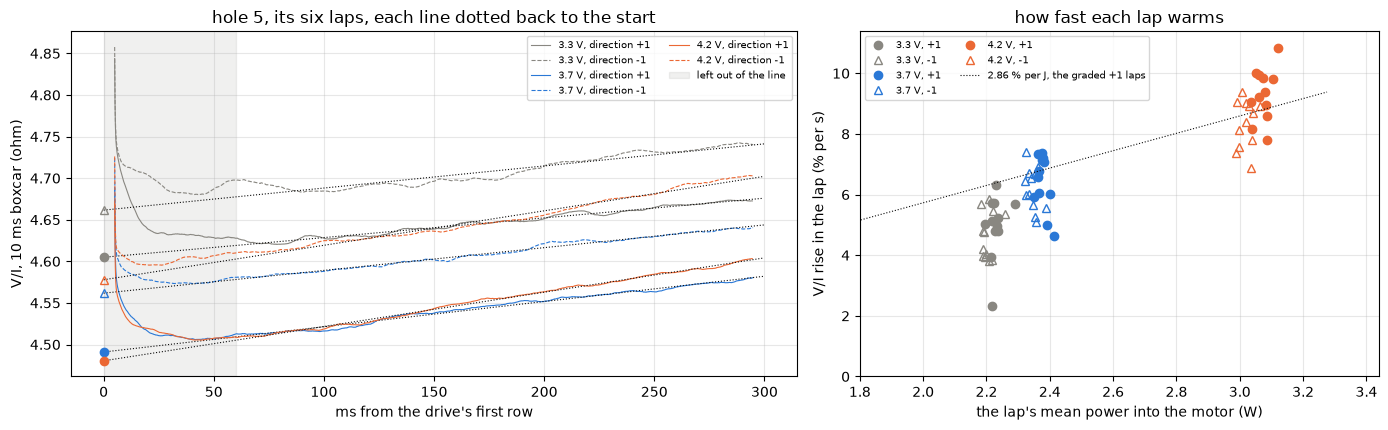

In [7]:
cold = S[S["graded"] & (S["dir"] == 1)]                                 # the graded laps of direction +1, the cleanest warming
by_level = S.groupby(["level", "dir"]).agg(rise_pct_per_s=("rise_pct_per_s", "mean"), watts=("watts", "mean"), pct_per_j=("pct_per_j", "mean"),
                                          early_pct=("early_pct", "mean"), early_lo=("early_pct", "min"), early_hi=("early_pct", "max"))
show(by_level.round(3).reset_index(), n=None)
ALPHA_CU, C_CU = 0.00393, 0.385                                          # pure copper: per C at 20 C, and J per g per C
PCT_PER_J = cold["pct_per_j"].mean()
C_MAX = ALPHA_CU * 100 / PCT_PER_J                                       # J/C if every ohm were copper and no heat left the copper in the lap
print(f"graded laps of direction +1: {PCT_PER_J:.2f} % per J ({cold['pct_per_j'].min():.2f} to {cold['pct_per_j'].max():.2f}), "
      f"{cold['rise_pct_per_s'].mean():.2f} %/s at {cold['watts'].mean():.2f} W on average")
print(f"so the copper holds at most {C_MAX:.3f} J/C, {C_MAX / C_CU:.2f} g of copper, if every ohm is copper; "
      f"with a share f of copper in the terminal resistance it is f^2 times that")
h0 = S[S["hole"] == 0]
print(f"hole 0's six laps: early window {h0['early_pct'].min():+.2f} to {h0['early_pct'].max():+.2f} % over the start, the other holes "
      f"{S[S['hole'] > 0]['early_pct'].min():+.2f} to {S[S['hole'] > 0]['early_pct'].max():+.2f} %")
v_motion = 0.01 * cold["r_start"].mean() * cold["i_start"].mean()        # the volts a 1 % excess of V/I stands for
print(f"a 1 % excess of V/I is {v_motion * 1e3:.0f} mV, which as back-EMF is {v_motion / KE:.0f} rad/s, "
      f"{v_motion / KE * 0.030 * 180 / np.pi:.0f} degrees of rotor over 30 ms")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
for v in LEVELS:
    for p in LAPS_RAW[(5, v)]:
        r = boxcar(p["volts"]) / boxcar(p["amps"])
        keep = slice(100, len(r) - 100)
        row = S[(S["hole"] == 5) & (S["level"] == v) & (S["dir"] == p["dir"])].iloc[0]
        ax[0].plot(p["t"][keep] * 1e3, r[keep], lw=0.8, color=COLOR[v], ls="-" if p["dir"] == 1 else "--",
                   label=f"{v:g} V, direction {p['dir']:+d}")
        tt = np.array([0, p["t"][-1]])
        ax[0].plot(tt * 1e3, row["r_start"] + row["r_slope"] * tt, lw=0.8, color=INK, ls=":")      # the fitted line, back to the start
        ax[0].plot(0, row["r_start"], MARK[p["dir"]], ms=6, color=COLOR[v], mfc=COLOR[v] if p["dir"] == 1 else "none")
ax[0].axvspan(0, FIT_FROM_S * 1e3, color=MUTED, alpha=0.12, label="left out of the line")
ax[0].set_xlabel("ms from the drive's first row"); ax[0].set_ylabel("V/I, 10 ms boxcar (ohm)")
ax[0].set_title("hole 5, its six laps, each line dotted back to the start"); ax[0].legend(fontsize=7, ncol=2); ax[0].grid(alpha=0.3)
for v in LEVELS:
    for d in (1, -1):
        g = S[(S["level"] == v) & (S["dir"] == d)]
        ax[1].plot(g["watts"], g["rise_pct_per_s"], MARK[d], ms=6, color=COLOR[v], mfc=COLOR[v] if d == 1 else "none",
                   label=f"{v:g} V, {d:+d}")
w = np.linspace(0, S["watts"].max() * 1.05, 10)
ax[1].plot(w, PCT_PER_J * w, color=INK, lw=0.8, ls=":", label=f"{PCT_PER_J:.2f} % per J, the graded +1 laps")
ax[1].set_xlim(left=1.8); ax[1].set_ylim(bottom=0)
ax[1].set_xlabel("the lap's mean power into the motor (W)"); ax[1].set_ylabel("V/I rise in the lap (% per s)")
ax[1].set_title("how fast each lap warms"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

After the early fall every lap of hole 5 runs on its line to the end, and the other holes look the same in the raw traces. The rate follows the power. The graded laps of direction +1 warm at 2.86 % per joule on average, 1.92 to 3.48 over the laps, about 7.9 % per second at 2.7 W. If every ohm of the terminal resistance were copper and the copper kept all its heat over the lap, a rate of 2.86 % per joule would mean a heat capacity of 0.137 J per C, about 0.36 g of copper. Only part of the resistance is copper, and with a share $f$ of copper the copper's heat capacity comes out $f^2$ times that. Some heat does leave the copper within the lap, the next section puts the time constant near 2 s, so the copper is most likely somewhat lighter still. The teardown can check this against the copper it reads.

The 3.3 V laps warm at 2.1 to 2.2 % per joule against 2.6 to 3.0 at the graded levels. The power differs by only about 6 % between 3.3 V and 3.7 V, so the copper alone does not explain a step of a fifth. The chain at 3.3 V drifting within the lap, or the contact still settling through the lap at the lowest current, would each flatten the slope. Neither is tested here, and the 3.3 V level carries no number.

The early fall is 0.86 % on average, the window from 2 to 20 ms against the start, from -0.83 to +2.22 % over the laps, and largest on the first lap at each hole, the 3.3 V lap of direction +1, at 1.5 % on average. Hole 0's six laps show almost none of it, -0.83 to +0.51 %. A rotor turning against the bar would read a back-EMF as extra resistance, but a 1 % excess is 35 mV, which at the bemf-coast constant is 30 rad/s, about 51 degrees of rotor over 30 ms. The bar holds the pinion, so the rotor is not turning that far and motion is not the cause, with high confidence. The board's chain answering the step in load is one candidate, and the motor is the other. Stage 1 ran the same 100 % laps on the same board into the bare resistor load, so the same reading over those laps checks the chain. Below, the stage 1 current-scale laps from `telemetry/dev-v006-2A-D/current-scale/capture-1/bare` at the same three levels and both directions, the first 400 ms of each 3 s lap, each lap's V/I over its own start, beside hole 5 of the motor read the same way. The thing to see is whether the resistor shows the fall.

,level,dir,amps,r_start,early_pct,slope_pct_per_s,span_pct
0,3.300,1,0.607,5.353,-0.081,-0.336,0.289
1,3.300,-1,0.605,5.345,0.068,0.194,0.301
2,3.700,1,0.628,5.169,0.102,0.027,0.284
3,3.700,-1,0.628,5.174,-0.091,-0.340,0.265
4,4.200,1,0.713,5.202,-0.014,0.034,0.138
5,4.200,-1,0.712,5.199,0.053,0.257,0.189


stage 1 bare resistor laps from telemetry/dev-v006-2A-D/current-scale/capture-1/bare: early window -0.09 to +0.10 % over the start, 10 ms V/I spans 0.14 to 0.30 % over the first 400 ms, slope -0.34 to +0.26 %/s, at 0.61 to 0.71 A
the motor's laps against the same reading: early window -0.83 to +2.22 %


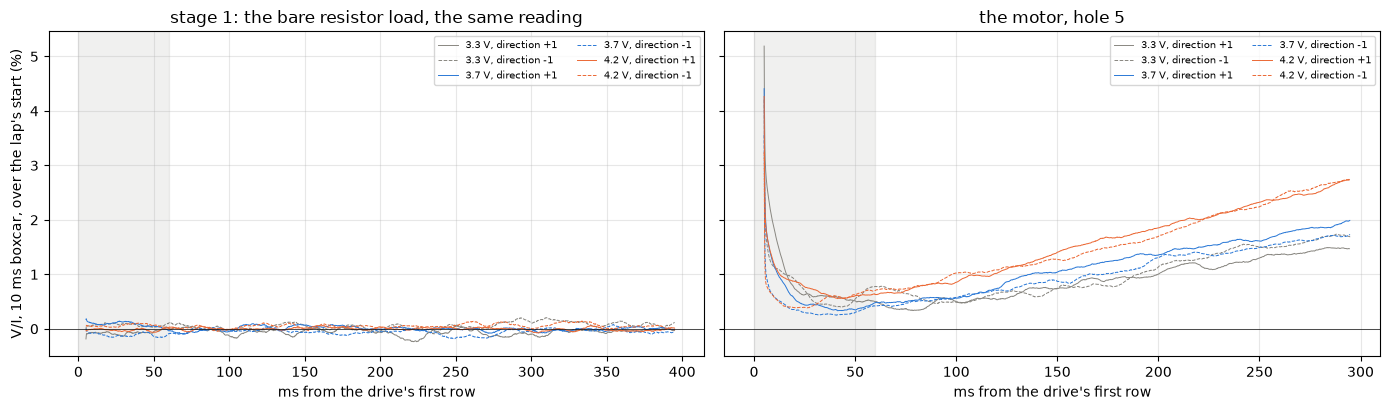

In [8]:
BARE = (Path("../../../telemetry") / BOARD.key / "current-scale" / "capture-1" / "bare").resolve()   # stage 1's 100 % laps into the bare resistor load
levels_r = pd.read_csv(BARE / "levels.csv")
SHOW_S = 0.400                                                           # the first 400 ms of each 3 s resistor lap, past the motor's 300 ms
rrows, curves = [], {}
for _, L in levels_r[levels_r["volts_set"].isin(LEVELS)].iterrows():
    df, meta = tel.load(BARE / L["folder"], BOARD)                       # checks the sense block against the board entry
    zero = float(tel.baseline(df)["current_raw"].median())              # the lap's own torque-off zero, as for the motor
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        d = int(g["dir"].iloc[0])
        on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])   # the drive's first row
        g = g.iloc[on:on + int(SHOW_S * FS)]
        i = (g["current_raw"].to_numpy(float) - zero - B_OFF) / G_CPA
        u = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - C_OFF) / K_CPV
        t = np.arange(len(g)) / FS
        fit = (t >= FIT_FROM_S) & (t <= 0.300)                           # the same window the motor's laps are read over
        pr = np.polyfit(t[fit], (u / i)[fit], 1)
        early = (t >= EARLY_S[0]) & (t < EARLY_S[1])
        r10 = boxcar(u) / boxcar(i)
        keep = slice(100, len(r10) - 100)
        curves[(float(L["volts_set"]), d)] = (t[keep], (r10[keep] / pr[1] - 1) * 100)
        rrows.append({"level": float(L["volts_set"]), "dir": d, "amps": i[early].mean(), "r_start": pr[1],
                      "early_pct": (u[early].mean() / i[early].mean() / pr[1] - 1) * 100,
                      "slope_pct_per_s": pr[0] / pr[1] * 100,
                      "span_pct": (np.nanmax(r10[keep]) - np.nanmin(r10[keep])) / pr[1] * 100})
RES = pd.DataFrame(rrows)
show(RES.round(4), n=None)
print(f"stage 1 bare resistor laps from {results.rel(BARE)}: early window {RES['early_pct'].min():+.2f} to {RES['early_pct'].max():+.2f} % over the start, "
      f"10 ms V/I spans {RES['span_pct'].min():.2f} to {RES['span_pct'].max():.2f} % over the first 400 ms, slope {RES['slope_pct_per_s'].min():+.2f} to "
      f"{RES['slope_pct_per_s'].max():+.2f} %/s, at {RES['amps'].min():.2f} to {RES['amps'].max():.2f} A")
print(f"the motor's laps against the same reading: early window {S['early_pct'].min():+.2f} to {S['early_pct'].max():+.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for (v, d), (t, pct) in curves.items():
    ax[0].plot(t * 1e3, pct, lw=0.7, color=COLOR[v], ls="-" if d == 1 else "--", label=f"{v:g} V, direction {d:+d}")
for v in LEVELS:
    for p in LAPS_RAW[(5, v)]:
        row = S[(S["hole"] == 5) & (S["level"] == v) & (S["dir"] == p["dir"])].iloc[0]
        r10 = boxcar(p["volts"]) / boxcar(p["amps"])
        keep = slice(100, len(r10) - 100)
        ax[1].plot(p["t"][keep] * 1e3, (r10[keep] / row["r_start"] - 1) * 100, lw=0.7, color=COLOR[v], ls="-" if p["dir"] == 1 else "--",
                   label=f"{v:g} V, direction {p['dir']:+d}")
ax[0].set_title("stage 1: the bare resistor load, the same reading"); ax[1].set_title("the motor, hole 5")
for a in ax:
    a.axvspan(0, FIT_FROM_S * 1e3, color=MUTED, alpha=0.12)
    a.axhline(0, color=INK, lw=0.5); a.set_xlabel("ms from the drive's first row"); a.grid(alpha=0.3); a.legend(fontsize=7, ncol=2)
ax[0].set_ylabel("V/I, 10 ms boxcar, over the lap's start (%)")
plt.tight_layout(); plt.show()

The resistor shows no fall. Its early window reads -0.09 to +0.10 % against the start over the six laps, at 0.61 to 0.71 A, and its V/I over 10 ms stays within 0.14 to 0.30 % from end to end of the first 400 ms, and its slope is -0.34 to +0.26 % per second. The motor's laps read -0.83 to +2.22 % in the same early window, and hole 5 starts 2 to 5 % over its start and falls to under 1 % within its first 50 ms before the warming takes over. The board, the chains, the reading and nearly the same current are common to both, so the fall belongs to the motor side, with high confidence.

What on the motor side is still open. The contact settling once the current flows, a film on the commutator that the current breaks down for example, is the candidate I favor, since the fall is largest on the first lap after the rotor moved and almost absent at hole 0, which also reads low. The winding itself is the other candidate, a slow tail in how the current builds through the iron, eddy currents in the laminations for example. That would not care about the rotor's last move, so it fits the pattern less well. Moderate confidence for the contact.

### The two directions

Every hole and level, the direction -1 lap's start less the direction +1 lap's start, against how much the +1 lap rose from its own start to its end. The graded levels are filled and the line through them is drawn. The thing to see is whether the gap follows the heat the first lap left behind.

,level,gap_pct,gap_pct_min,gap_pct_max,gap_mohm,rise_mohm,kept,gap_mv
0,3.300,0.786,-1.131,1.880,35.831,68.237,0.587,25.193
1,3.700,1.136,0.559,1.659,50.734,86.021,0.542,37.162
2,4.200,1.650,1.122,2.204,73.498,124.198,0.575,61.390


direction -1 over +1 at the start: +1.19 % on average, -1.13 to +2.20 %, 35 of 36 laps higher
graded levels: gap = 0.590 +/- 0.026 x rise with no offset, a time constant of 1.9 s over the 1 s rest; with a free offset 0.58 +/- 0.13 x rise +1.6 +/- 13.7 mohm
  3.3 V: correlation of gap and rise over the holes +0.72
  3.7 V: correlation of gap and rise over the holes +0.58
  4.2 V: correlation of gap and rise over the holes +0.20
graded laps warm at 2.86 % per J in direction +1 and 2.70 % per J in direction -1


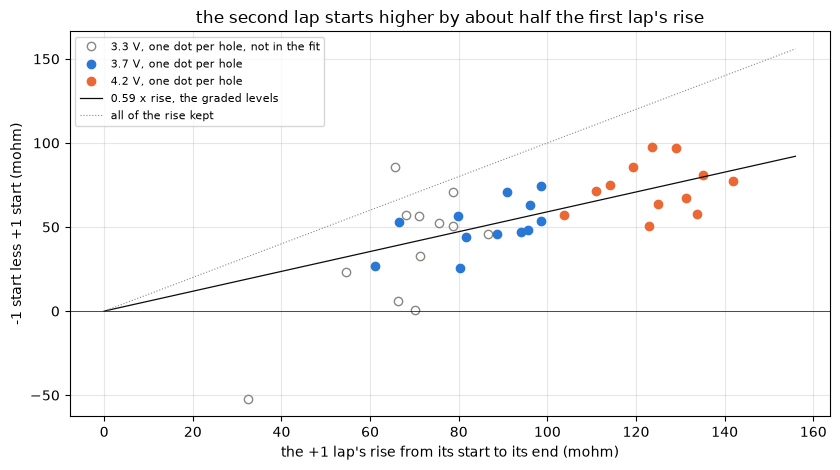

In [9]:
P = S[S["dir"] == 1].set_index(["hole", "level"])
M = S[S["dir"] == -1].set_index(["hole", "level"])
D = pd.DataFrame({"gap": M["r_start"] - P["r_start"], "rise": P["rise"], "r_start": P["r_start"], "i_start": P["i_start"]}).reset_index()
D["gap_pct"] = D["gap"] / D["r_start"] * 100
D["kept"] = D["gap"] / D["rise"]                                         # the share of the +1 lap's rise the -1 lap starts with
Dg = D[D["level"] >= RAIL_GRADED_V]                                      # the graded levels; the 3.3 V +1 lap is the first after a move
KEPT = float((Dg["gap"] * Dg["rise"]).sum() / (Dg["rise"] ** 2).sum())   # the gap as a share of the rise, no offset: heat alone
KEPT_SE = float(np.sqrt(((Dg["gap"] - KEPT * Dg["rise"]) ** 2).sum() / (len(Dg) - 1) / (Dg["rise"] ** 2).sum()))
ret = laps.line(Dg["rise"], Dg["gap"])                                   # the same with a free offset, which a polarity effect would need
TAU_S = -1.0 / np.log(KEPT)                                              # an exponential that keeps that share over the 1 s rest
show(D.groupby("level").agg(gap_pct=("gap_pct", "mean"), gap_pct_min=("gap_pct", "min"), gap_pct_max=("gap_pct", "max"),
                            gap_mohm=("gap", "mean"), rise_mohm=("rise", "mean"), kept=("kept", "median"),
                            gap_mv=("gap", lambda g: (g * D.loc[g.index, "i_start"]).mean()))
     .assign(gap_mohm=lambda x: x["gap_mohm"] * 1e3, rise_mohm=lambda x: x["rise_mohm"] * 1e3, gap_mv=lambda x: x["gap_mv"] * 1e3).round(3).reset_index(), n=None)
print(f"direction -1 over +1 at the start: {D['gap_pct'].mean():+.2f} % on average, {D['gap_pct'].min():+.2f} to {D['gap_pct'].max():+.2f} %, "
      f"{int((D['gap'] > 0).sum())} of {len(D)} laps higher")
print(f"graded levels: gap = {KEPT:.3f} +/- {KEPT_SE:.3f} x rise with no offset, a time constant of {TAU_S:.1f} s over the 1 s rest; "
      f"with a free offset {ret['slope']:.2f} +/- {ret['slope_se']:.2f} x rise {ret['intercept'] * 1e3:+.1f} +/- {ret['intercept_se'] * 1e3:.1f} mohm")
for v in LEVELS:
    g = D[D["level"] == v]
    print(f"  {v:g} V: correlation of gap and rise over the holes {np.corrcoef(g['rise'], g['gap'])[0, 1]:+.2f}")
rate = S[S["graded"]].groupby("dir")[["rise_pct_per_s", "watts", "pct_per_j"]].mean()
print(f"graded laps warm at {rate.loc[1, 'pct_per_j']:.2f} % per J in direction +1 and {rate.loc[-1, 'pct_per_j']:.2f} % per J in direction -1")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for v in LEVELS:
    g = D[D["level"] == v]
    graded = v >= RAIL_GRADED_V
    ax.plot(g["rise"] * 1e3, g["gap"] * 1e3, "o", ms=6, color=COLOR[v], mfc=COLOR[v] if graded else "none",
            label=f"{v:g} V, one dot per hole" + ("" if graded else ", not in the fit"))
x = np.linspace(0, D["rise"].max() * 1.1, 10)
ax.plot(x * 1e3, KEPT * x * 1e3, color=INK, lw=0.9, label=f"{KEPT:.2f} x rise, the graded levels")
ax.plot(x * 1e3, x * 1e3, color=MUTED, lw=0.8, ls=":", label="all of the rise kept")
ax.axhline(0, color=INK, lw=0.5)
ax.set_xlabel("the +1 lap's rise from its start to its end (mohm)"); ax.set_ylabel("-1 start less +1 start (mohm)")
ax.set_title("the second lap starts higher by about half the first lap's rise"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Direction -1 starts 1.19 % over direction +1 on average, from -1.13 to +2.20 %, and higher in 35 of 36 pairs. The gap grows with the level, 0.79 % at 3.3 V, 1.14 % at 3.7 V and 1.65 % at 4.2 V. At every level the gap is close to the same share of the +1 lap's own rise, 0.54 to 0.59 in the median. Through the graded levels with no offset the gap is $0.590 \pm 0.026$ times the rise. With a free offset the line keeps 0.58 of the rise and leaves +1.6 +/- 13.7 mohm at zero rise.

Two candidates were open, the direction itself at the brushes and the heat carried from the first lap. Both put the second lap higher, and the data favors the heat. A contact whose drop differs with the direction of the current would give the same gap in volts at every level, or the same gap in ohms. The gap here is 25 mV at 3.3 V, 37 mV at 3.7 V and 61 mV at 4.2 V, and 36, 51 and 74 mohm, so it grows faster than either. It follows the rise lap by lap inside a level as well, with correlations of +0.72 at 3.3 V and +0.58 at 3.7 V, and +0.20 at 4.2 V, where the link lap by lap is weak. And the direction -1 laps warm a little slower, 2.70 % per joule against 2.86, which is what a lap that starts warm and loses heat to the iron faster would show. A part from the direction itself is not needed. Within the offset's error it is under about 15 mohm, 0.3 % of the reading. I hold the heat as the main cause with moderate to high confidence.

If the gap is the heat, the copper keeps 59 % of its excess over the second of rest, which an exponential does with a time constant of about 1.9 s. That is the copper giving its heat to the rotor's iron, which is most likely several times heavier, and it means each lap starts on the heat of the laps before it to some degree. The direction -1 lap starts on most of the +1 lap's heat. The next level's +1 lap starts several seconds after the last -1 lap ends, when the copper has given most of its excess to the iron, and the iron's own warming stays. How much that is the capture does not show, and it matters for the brush drop below. Running direction -1 first, or swapping the motor's leads at the board's connector, separates the two candidates directly, and the Open questions carry both.

### The resistance over the rotor's angle

Each hole's $V/I$ at the start of its direction +1 laps, the mean of the 3.7 V and 4.2 V laps with the two as whiskers, beside direction -1 the same way, against the rotor's angle. Under it the rest the motor had before each hole. The thing to see is how much the reading moves with the angle, and what it moves with.

,hole,angle_deg,r_plus,r_plus_lo,r_plus_hi,r_minus,i_plus,gap_s,r33_plus,r33_minus,map_pct
0,0,0,4.384,4.367,4.400,4.436,0.796,NaN,4.438,4.490,-1.610
1,1,30,4.452,4.439,4.466,4.514,0.785,125.659,4.571,4.617,-0.062
2,2,60,4.443,4.442,4.444,4.498,0.786,168.239,4.624,4.572,-0.268
3,3,90,4.407,4.396,4.417,4.484,0.792,122.900,4.588,4.594,-1.089
4,4,120,4.450,4.443,4.456,4.524,0.786,193.888,4.564,4.650,-0.128
5,5,150,4.486,4.480,4.491,4.570,0.781,60.360,4.605,4.662,0.682
6,6,180,4.492,4.485,4.498,4.543,0.779,60.270,4.601,4.652,0.814
7,7,210,4.531,4.530,4.532,4.569,0.773,70.636,4.662,4.662,1.696
8,8,240,4.510,4.491,4.529,4.583,0.776,75.052,4.589,4.660,1.224
9,9,270,4.458,4.453,4.463,4.519,0.784,81.746,4.574,4.631,0.062


terminal V/I at the start, direction +1, graded levels: median 4.455 ohm over the holes, 4.384 (hole 0) to 4.531 (hole 7), -1.61 to +1.70 % about the median; direction -1 median 4.521 ohm
the four graded laps' maps, holes 1 to 11: correlation 0.85 to 0.95; scatter about each hole's mean 0.24 % on average
the 3.3 V maps against the graded ones: direction +1 0.44 to 0.63, direction -1 0.76 to 0.90
by parity, the 60 degree test: even holes -0.03 % (-1.61 to +1.22), odd holes +0.37 % (-1.09 to +1.70)
each hole against the hole 180 degrees on: correlation +0.25; against the hole 120 degrees on: -0.39
holes after a gap over 100 s (1 to 4): -0.39 %; after a gap under 100 s (5 to 11): +0.74 %; hole 0, the first: -1.61 %
one hole puts 4.6 J into the motor: 27 mW on average over holes 1 to 4 and 52 mW over 5 to 11; a 1.13 % step is 2.9 C of copper, which 26 mW more would give through 112 C/W from the motor to the room


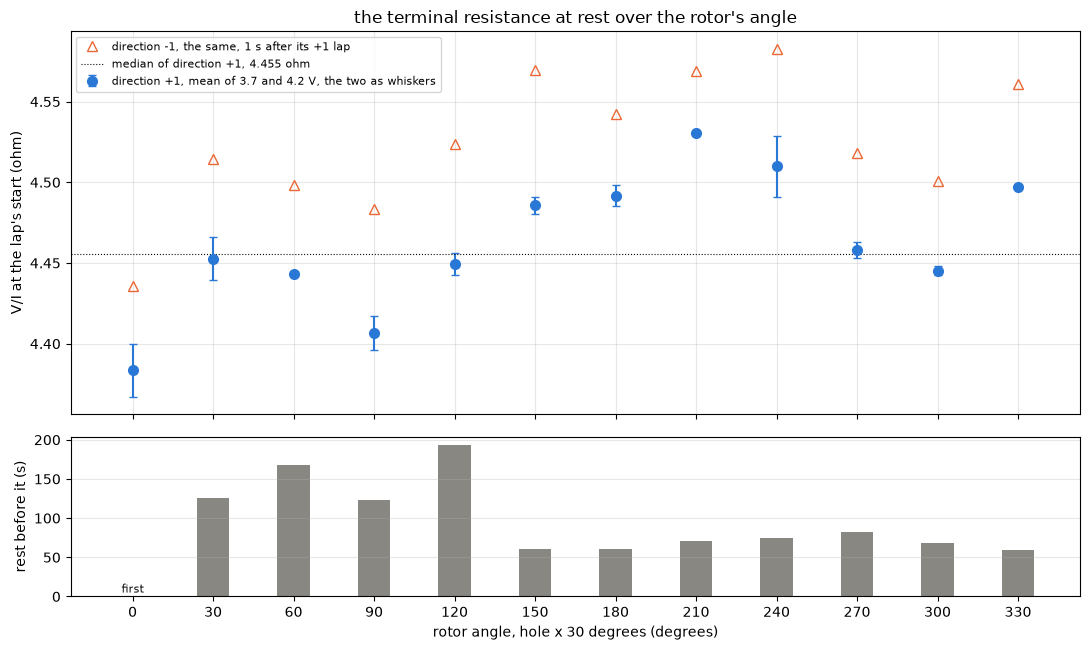

In [10]:
G = S[S["graded"]]
MAP = G.pivot_table(index="hole", columns=["dir", "level"], values="r_start")      # V/I at the start, one column per graded lap
HOLE = pd.DataFrame({"angle_deg": DEG_PER_HOLE * MAP.index, "r_plus": MAP[1].mean(axis=1), "r_plus_lo": MAP[1].min(axis=1), "r_plus_hi": MAP[1].max(axis=1),
                     "r_minus": MAP[-1].mean(axis=1), "i_plus": G[G["dir"] == 1].groupby("hole")["i_start"].mean(),
                     "gap_s": GAP_S, "r33_plus": S[(S["level"] == 3.3) & (S["dir"] == 1)].set_index("hole")["r_start"],
                     "r33_minus": S[(S["level"] == 3.3) & (S["dir"] == -1)].set_index("hole")["r_start"]})
R_TERM = float(HOLE["r_plus"].median())
NORM = S.pivot_table(index="hole", columns=["level", "dir"], values="r_start")
NORM = NORM / NORM.median()                                              # every lap's map over its own median, so the levels can be compared
HOLE["map_pct"] = (HOLE["r_plus"] / R_TERM - 1) * 100
show(HOLE.round(4).reset_index(), n=None)
graded_cols = [c for c in NORM.columns if c[0] >= RAIL_GRADED_V]
corr = NORM.loc[1:, graded_cols].corr().to_numpy()                       # how alike the graded laps' maps are, hole 0 left out
REPEAT_PCT = float(NORM[graded_cols].std(axis=1).mean() * 100)           # the laps' scatter about each hole's mean, in % of the reading
print(f"terminal V/I at the start, direction +1, graded levels: median {R_TERM:.3f} ohm over the holes, {HOLE['r_plus'].min():.3f} (hole "
      f"{HOLE['r_plus'].idxmin()}) to {HOLE['r_plus'].max():.3f} (hole {HOLE['r_plus'].idxmax()}), "
      f"{HOLE['map_pct'].min():+.2f} to {HOLE['map_pct'].max():+.2f} % about the median; direction -1 median {HOLE['r_minus'].median():.3f} ohm")
print(f"the four graded laps' maps, holes 1 to 11: correlation {corr[np.triu_indices(len(corr), 1)].min():.2f} to {corr[np.triu_indices(len(corr), 1)].max():.2f}; "
      f"scatter about each hole's mean {REPEAT_PCT:.2f} % on average")
c33 = NORM.loc[1:].corr()
print(f"the 3.3 V maps against the graded ones: direction +1 {c33.loc[(3.3, 1), graded_cols].min():.2f} to {c33.loc[(3.3, 1), graded_cols].max():.2f}, "
      f"direction -1 {c33.loc[(3.3, -1), graded_cols].min():.2f} to {c33.loc[(3.3, -1), graded_cols].max():.2f}")
even, odd = HOLE[HOLE.index % 2 == 0]["map_pct"], HOLE[HOLE.index % 2 == 1]["map_pct"]
print(f"by parity, the 60 degree test: even holes {even.mean():+.2f} % ({even.min():+.2f} to {even.max():+.2f}), odd holes {odd.mean():+.2f} % ({odd.min():+.2f} to {odd.max():+.2f})")
opp = HOLE["map_pct"].to_numpy()
print(f"each hole against the hole 180 degrees on: correlation {np.corrcoef(opp[:6], opp[6:])[0, 1]:+.2f}; "
      f"against the hole 120 degrees on: {np.corrcoef(opp, np.roll(opp, -4))[0, 1]:+.2f}")
short = HOLE["gap_s"] < 100
print(f"holes after a gap over 100 s (1 to 4): {HOLE[~short & (HOLE.index > 0)]['map_pct'].mean():+.2f} %; after a gap under 100 s (5 to 11): "
      f"{HOLE[short]['map_pct'].mean():+.2f} %; hole 0, the first: {HOLE.loc[0, 'map_pct']:+.2f} %")

J_HOLE = S.groupby("hole")["joules"].sum().mean()                         # what one hole's six laps put into the motor
cycle = HOLE["gap_s"] + (last - first).shift(1)                                 # seconds from one hole's start to the next, rests and sweeps
w_long, w_short = J_HOLE / cycle[1:5].mean(), J_HOLE / cycle[5:].mean()   # the mean power into the motor over each stretch of the pass
step = HOLE[short]["map_pct"].mean() - HOLE[~short & (HOLE.index > 0)]["map_pct"].mean()
print(f"one hole puts {J_HOLE:.1f} J into the motor: {w_long * 1e3:.0f} mW on average over holes 1 to 4 and {w_short * 1e3:.0f} mW over 5 to 11; "
      f"a {step:.2f} % step is {step / (ALPHA_CU * 100):.1f} C of copper, which {(w_short - w_long) * 1e3:.0f} mW more would give through "
      f"{step / (ALPHA_CU * 100) / (w_short - w_long):.0f} C/W from the motor to the room")
fig, ax = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
a = ax[0]
a.errorbar(HOLE["angle_deg"], HOLE["r_plus"], yerr=[HOLE["r_plus"] - HOLE["r_plus_lo"], HOLE["r_plus_hi"] - HOLE["r_plus"]], fmt="o", ms=7,
           color=BLUE, capsize=3, label="direction +1, mean of 3.7 and 4.2 V, the two as whiskers")
a.plot(HOLE["angle_deg"], HOLE["r_minus"], "^", ms=7, color=ORANGE, mfc="none", label="direction -1, the same, 1 s after its +1 lap")
a.axhline(R_TERM, color=INK, lw=0.8, ls=":", label=f"median of direction +1, {R_TERM:.3f} ohm")
a.set_ylabel("V/I at the lap's start (ohm)"); a.set_title("the terminal resistance at rest over the rotor's angle"); a.legend(fontsize=8); a.grid(alpha=0.3)
ax[1].bar(HOLE["angle_deg"], HOLE["gap_s"].fillna(0), width=12, color=MUTED)
ax[1].annotate("first", (0, 5), ha="center", fontsize=8, color=INK)
ax[1].set_ylabel("rest before it (s)"); ax[1].set_xlabel("rotor angle, hole x 30 degrees (degrees)")
ax[1].set_xticks(HOLE["angle_deg"]); ax[1].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

The terminal resistance at rest reads 4.455 ohm in the median over the twelve holes, at about 0.78 A with the brush drop included, from 4.384 ohm at hole 0 to 4.531 ohm at hole 7. That is -1.61 to +1.70 % about the median, 3.3 % from the lowest hole to the highest. Direction -1 reads 4.521 ohm in the median, 1.5 % higher, and follows the same shape, which is the carried heat from the last section.

The shape over the holes is real for this pass. The four graded laps of each hole give maps that correlate 0.85 to 0.95 with each other over holes 1 to 11, and they scatter 0.24 % about each hole's mean, against the 3.3 % the map spans. The 3.3 V -1 laps follow the same map, with correlations of 0.76 to 0.90. The 3.3 V +1 laps, the first current after each move of the bar, follow it much less, 0.44 to 0.63. So the first lap after a move reads with a scatter of its own, most likely the contact settling, the same thing the early fall points at.

What the map moves with is less clear. Two candidates fit parts of it.

- The brush contact over the commutator, the reading changing with which segments sit under the brushes and how. With three segments and two brushes the geometry under the brushes repeats every 60 degrees on an even commutator. Holes 30 degrees apart sample that pattern at two phases only, the even holes at one and the odd holes at the other. The even holes read -0.03 % on average and the odd ones +0.37 %, with each group spreading -1.6 to +1.7 %, so the 60 degree pattern is not what spreads the holes. The hole 180 degrees on correlates +0.25 and the hole 120 degrees on -0.39, so no clean repeat at a half or a third of a turn either. What the angle owns, if it owns the spread, is the particular segments and brushes, a segment edge or a brush that sits differently at one place. Neighboring holes with similar rests do step against each other, hole 3 at -1.1 % between holes 2 and 4 at -0.3 and -0.1 %, and hole 10 at -0.2 % between hole 9 at +0.1 and hole 11 at +0.9 %. Steps of half a percent to a percent between neighbors are several times the 0.24 % scatter, and the angle is the likely owner of those.
- The motor warming over the pass. The holes ran in order, so the angle and the clock are the same axis here. Holes 1 to 4 read -0.39 % on average after rests of two to three minutes, holes 5 to 11 read +0.74 % after rests of about a minute, and hole 0, the first of the pass with no heat before it, reads -1.61 %. One hole puts about 4.6 J into the motor, 27 mW on average over holes 1 to 4 and 52 mW over holes 5 to 11. The 1.13 % step between the two stretches is 2.9 C of copper, which the extra 26 mW gives through about 110 C/W from the motor to the room. Natural convection off a can of about 10 square centimeters in still air gives about 100 C/W, so the figure is plausible, so the hump of holes 5 to 8 and the low hole 0 fit the heat as well, with low to moderate confidence.

Two readings of this pass stand against each other. One, the rig's maker's, is that a hole change is slow, a minute or more with the bar out, so the warming between holes is negligible and the map and the direction gap both belong to the brush contact over the segments. The other is what the laps themselves say about heat: a lap warms the copper 1 to 3 % in 300 ms, the second lap of a pair starts on 59 % of the first lap's rise a second later, and the holes read after the short rests sit 0.7 % over those read after the long ones. The next figure puts one warming body against the map, with its time constant free, and leaves what it cannot explain to the angle, so the figure and not the prior decides how the map splits.

My working reading going in was that the spread is the brush contact over the segments. The data supports a part of it that belongs to the angle, the steps between neighbors. The broad hump and the low first hole follow the clock as closely as the angle, and this pass does not separate them, since every hole was read once and in order. One thing does point at the contact for hole 0. Its laps differ in shape, no early fall at 3.3 V and a wobble at 3.7 V, and a temperature moves the level of a reading and not its shape. A brush resting partly on the next segment at that angle is one way to get a low and unsteady reading, and that is a guess.

The ring connection the teardown assumes predicts that a hole where one brush spans the gap between two segments reads about three quarters of the others. No hole reads anywhere near that, so none of the twelve holes caught a brush across a gap, which fits a gap that is narrow against 30 degrees, or both sampled phases sitting away from it.

### The brush drop and the 3.3 V level

Left, $V/I$ at the start against $1/I$ for every hole's direction +1 laps, the graded pair of each hole joined, the 3.3 V point as read and divided by the stage 1 factor, and dotted guides for a brush drop of 0, 0.2 and 0.4 V. Right, each hole's $V_0$ from its own line, by which levels the line runs through, both directions. The thing to see is how much the intercept depends on the 3.3 V level and how wide it spreads with the graded levels alone.

### One warming body against the map

A single body, the motor as one lump, warmed by every sweep's joules and cooling to the room with one time constant $\tau$, read at each hole's 3.7 V sweep where the graded +1 laps are. For each $\tau$ from 30 s to 20 min the heat the body still holds at each read is a line's worth of the map, and the $\tau$ that leaves the least residual is kept. Left, the map over the angle with what the body's heat alone would read, right, what is left once it is taken out, with the even and odd holes marked, which is where a 60 degree pattern would show. The thing to see is how much of the map one body explains, with what time constant, and whether what is left has any shape in the angle.

one body: tau 90 s (rms 0.56 %; within 10 % of it from 40 to 220 s), 0.716 % per joule held, so a body of 0.5 J/C if the slope is copper warming; it explains 62 % of the map's variance and reads 2.14 % from the coldest hole to the warmest
left for the angle: -0.99 to +0.87 %, sd 0.59 %, against 0.24 % of lap scatter; even holes -0.02 %, odd +0.02 %; against the hole 120 degrees on -0.39, 180 degrees on +0.16; hole 0 -0.53 %


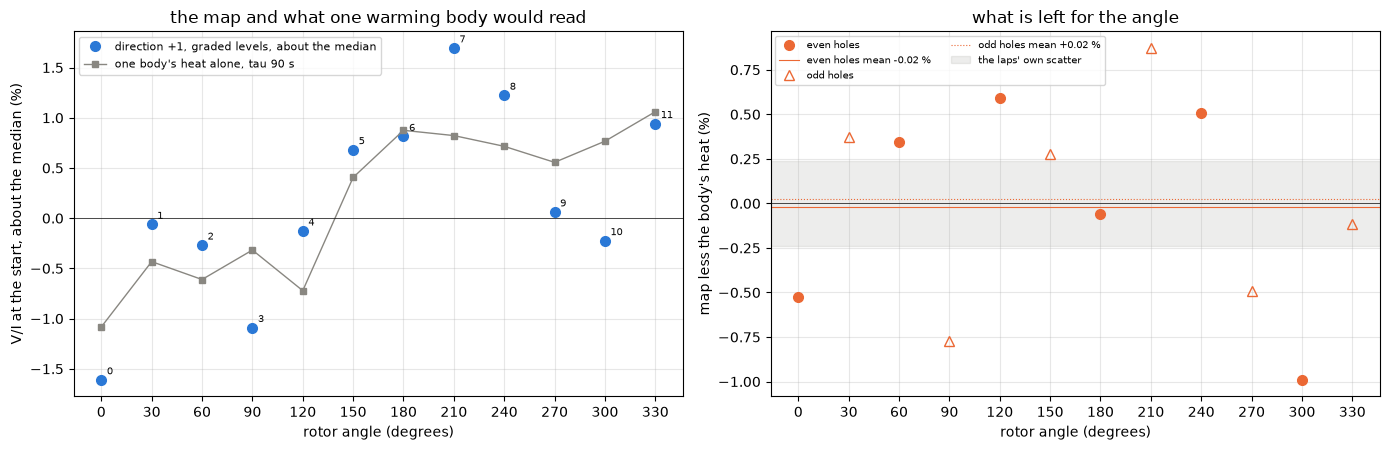

In [11]:
E_SWEEP = S.groupby(["hole", "level"])["joules"].sum()                                 # joules per sweep, both directions
SW = lapdf.assign(t=lapdf["t_start"] - T0, joules=[float(E_SWEEP[(int(k), float(v))]) for k, v in zip(lapdf["hole"], lapdf["volts_set"])])
T_READ = SW[SW["volts_set"] == 3.7].set_index("hole")["t"]                              # when each hole's graded laps begin

def heat_at(tau):
    # the joules the body still holds at each hole's read: every earlier sweep's joules decayed over the time since
    return pd.Series({k: sum(j * np.exp(-(T_READ[k] - t) / tau) for t, j in zip(SW["t"], SW["joules"]) if t < T_READ[k]) for k in T_READ.index})

TAUS = np.arange(30, 1201, 10)
FITS = pd.DataFrame([{"tau": tau, **{k: v for k, v in laps.line(heat_at(tau).loc[HOLE.index], HOLE["map_pct"]).items() if k in ("slope", "intercept", "rms")}} for tau in TAUS])
best = FITS.loc[FITS["rms"].idxmin()]
TAU_BODY = float(best["tau"])
H_BEST = heat_at(TAU_BODY).loc[HOLE.index]
HOLE["heat_pct"] = best["intercept"] + best["slope"] * H_BEST                           # what the body's heat alone would read, about the median
HOLE["angle_pct"] = HOLE["map_pct"] - HOLE["heat_pct"]                                   # what is left for the angle
HEAT_SHARE = 1 - HOLE["angle_pct"].var() / HOLE["map_pct"].var()
C_BODY = 1 / (best["slope"] / (ALPHA_CU * 100))                                          # J per C of the body, if the slope is copper warming
even_r, odd_r = HOLE[HOLE.index % 2 == 0]["angle_pct"], HOLE[HOLE.index % 2 == 1]["angle_pct"]
res = HOLE["angle_pct"].to_numpy()
print(f"one body: tau {TAU_BODY:.0f} s (rms {best['rms']:.2f} %; within 10 % of it from {FITS[FITS['rms'] <= best['rms'] * 1.1]['tau'].min():.0f} to "
      f"{FITS[FITS['rms'] <= best['rms'] * 1.1]['tau'].max():.0f} s), {best['slope']:.3f} % per joule held, so a body of {C_BODY:.1f} J/C if the slope is copper warming; "
      f"it explains {HEAT_SHARE * 100:.0f} % of the map's variance and reads {HOLE['heat_pct'].max() - HOLE['heat_pct'].min():.2f} % from the coldest hole to the warmest")
print(f"left for the angle: {HOLE['angle_pct'].min():+.2f} to {HOLE['angle_pct'].max():+.2f} %, sd {HOLE['angle_pct'].std():.2f} %, against {REPEAT_PCT:.2f} % of lap scatter; "
      f"even holes {even_r.mean():+.2f} %, odd {odd_r.mean():+.2f} %; against the hole 120 degrees on {np.corrcoef(res, np.roll(res, -4))[0, 1]:+.2f}, "
      f"180 degrees on {np.corrcoef(res[:6], res[6:])[0, 1]:+.2f}; hole 0 {HOLE.loc[0, 'angle_pct']:+.2f} %")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(HOLE["angle_deg"], HOLE["map_pct"], "o", ms=7, color=BLUE, label="direction +1, graded levels, about the median")
ax[0].plot(HOLE["angle_deg"], HOLE["heat_pct"], "s-", ms=5, lw=1, color=MUTED, label=f"one body's heat alone, tau {TAU_BODY:.0f} s")
for k in HOLE.index:
    ax[0].annotate(str(k), (HOLE.loc[k, "angle_deg"], HOLE.loc[k, "map_pct"]), fontsize=7, xytext=(4, 4), textcoords="offset points", color=INK)
ax[0].axhline(0, color=INK, lw=0.5); ax[0].set_xlabel("rotor angle (degrees)"); ax[0].set_ylabel("V/I at the start, about the median (%)")
ax[0].set_title("the map and what one warming body would read"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3); ax[0].set_xticks(HOLE["angle_deg"])
for par, mk, lab in ((0, "o", "even holes"), (1, "^", "odd holes")):
    h = HOLE[HOLE.index % 2 == par]
    ax[1].plot(h["angle_deg"], h["angle_pct"], mk, ms=7, color=ORANGE, mfc=ORANGE if par == 0 else "none", label=lab)
    ax[1].axhline(h["angle_pct"].mean(), color=ORANGE, lw=0.8, ls="-" if par == 0 else ":", label=f"{lab} mean {h['angle_pct'].mean():+.2f} %")
ax[1].axhspan(-REPEAT_PCT, REPEAT_PCT, color=MUTED, alpha=0.15, label="the laps' own scatter")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlabel("rotor angle (degrees)"); ax[1].set_ylabel("map less the body's heat (%)")
ax[1].set_title("what is left for the angle"); ax[1].legend(fontsize=7, ncol=2); ax[1].grid(alpha=0.3); ax[1].set_xticks(HOLE["angle_deg"])
plt.tight_layout(); plt.show()

One body with a time constant of about 90 s, anywhere from 40 to 220 s within a tenth of the best residual, explains 62 % of the map's variance. Its heat alone reads 2.1 % from the coldest hole, hole 0 with nothing before it, to the warmest, holes 7 and 8 after the short rests, and the slope it needs, 0.7 % per joule held, is a body of about 0.5 J per degree if the slope is copper warming, a rotor's worth and not the whole motor's, which fits a time constant of a minute or two: the copper and the iron it sits in warm and cool together faster than the can. So the warming between holes is not negligible on this pass. A hole change is slow, but one hole's six laps put 4.6 J into a small body, and the next hole starts a minute later with a third of it still there.

What is left for the angle is -1.0 to +0.9 % over the holes, sd 0.6 %, two and a half times the laps' own scatter of 0.24 %, so the angle owns a real part. It has no shape the commutator would give it. The even and odd holes, the two phases of a 60 degree pattern, sit within 0.05 % of each other, and the hole 120 degrees on correlates -0.39, the one 180 degrees on +0.16, no repeat at a third or a half of a turn. What the angle owns reads as the particular place each hole lands, a segment edge or a brush that sits differently there, the steps between neighbors, and not as a pattern. Hole 0 keeps -0.5 % after the body's heat is taken out, so part of its low reading is the cold start and part is its own, and its laps' shape, the missing early fall and the wobble, still points at the contact at that angle. The split is one model's, moderate confidence on the share and low on the time constant; a pass in another order is what settles it, as the Open questions say.

,levels,dir,r_median,r_min,r_max,v0_median,v0_min,v0_max,v0_mean,v0_se,amps_span
0,3.7 and 4.2 V,1,4.401,4.153,4.829,0.060,-0.246,0.183,0.045,0.031,0.102
1,3.7 and 4.2 V,-1,4.596,4.518,4.875,-0.086,-0.221,-0.002,-0.091,0.022,0.097
2,"all three, 3.3 V as read",1,3.965,3.630,4.343,0.408,0.145,0.633,0.412,0.036,0.135
3,"all three, 3.3 V as read",-1,4.187,4.053,4.413,0.261,0.119,0.379,0.263,0.024,0.127
4,"all three, 3.3 V scaled",1,4.655,4.301,5.091,-0.146,-0.457,0.082,-0.146,0.038,0.135
5,"all three, 3.3 V scaled",-1,4.897,4.769,5.169,-0.317,-0.465,-0.193,-0.316,0.026,0.127


between the graded levels 1/I moves by 0.167 per A, so 0.1 % of V/I between the two laps moves V0 by 27 mV
the 3.3 V laps read +2.45 % over the graded laps of their hole and direction (+1.22 to +4.11); stage 1 puts +3.9 % of V/I at that level on the chain, and a brush drop of 0.1 V would add 0.3 %


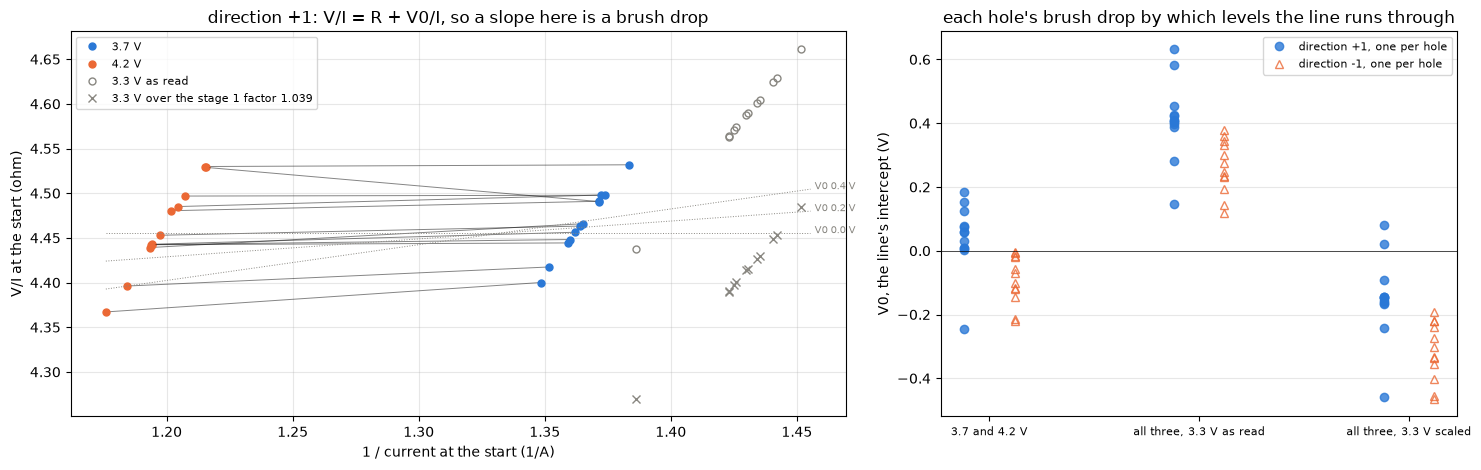

In [12]:
def hole_lines(levels, scale_3v3=1.0):
    # the line V = V0 + R I through one hole's laps of one direction, at the drive's start, over the given levels;
    # the 3.3 V volts divided by scale_3v3, the stage 1 factor, when it is not 1
    out = []
    for (k, d), g in S[S["level"].isin(levels)].groupby(["hole", "dir"]):
        v = np.where(g["level"] < RAIL_GRADED_V, g["v_start"] / scale_3v3, g["v_start"])
        f = laps.line(g["i_start"], v)
        out.append({"hole": k, "dir": d, "r": f["slope"], "v0": f["intercept"], "di": g["i_start"].max() - g["i_start"].min()})
    return pd.DataFrame(out)


VARIANTS = {"3.7 and 4.2 V": hole_lines([3.7, 4.2]), "all three, 3.3 V as read": hole_lines(LEVELS),
            "all three, 3.3 V scaled": hole_lines(LEVELS, F_3V3)}
summary = []
for name, L in VARIANTS.items():
    for d in (1, -1):
        g = L[L["dir"] == d]
        summary.append({"levels": name, "dir": d, "r_median": g["r"].median(), "r_min": g["r"].min(), "r_max": g["r"].max(),
                        "v0_median": g["v0"].median(), "v0_min": g["v0"].min(), "v0_max": g["v0"].max(), "v0_mean": g["v0"].mean(),
                        "v0_se": g["v0"].std() / np.sqrt(len(g)), "amps_span": g["di"].mean()})
SUM = pd.DataFrame(summary)
show(SUM.round(3), n=None)
LINE_P = VARIANTS["3.7 and 4.2 V"].query("dir == 1").set_index("hole")   # the result's line: direction +1, the graded levels
lever = 1 / S[(S["level"] == 3.7) & (S["dir"] == 1)]["i_start"].mean() - 1 / S[(S["level"] == 4.2) & (S["dir"] == 1)]["i_start"].mean()
print(f"between the graded levels 1/I moves by {lever:.3f} per A, so 0.1 % of V/I between the two laps moves V0 by "
      f"{0.001 * R_TERM / lever * 1e3:.0f} mV")
r33 = S[S["level"] == 3.3].set_index(["hole", "dir"])["r_start"]
rg = S[S["graded"]].groupby(["hole", "dir"])["r_start"].mean()
EXCESS_3V3 = (r33 / rg - 1) * 100                                         # the 3.3 V lap over the graded laps of the same hole and direction
print(f"the 3.3 V laps read {EXCESS_3V3.median():+.2f} % over the graded laps of their hole and direction ({EXCESS_3V3.min():+.2f} to {EXCESS_3V3.max():+.2f}); "
      f"stage 1 puts {(F_3V3 - 1) * 100:+.1f} % of V/I at that level on the chain, and a brush drop of 0.1 V would add "
      f"{0.1 * (1 / S[S['level'] == 3.3]['i_start'].mean() - 1 / S[S['graded']]['i_start'].mean()) / R_TERM * 100:.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
a = ax[0]
for k in range(12):
    g = S[(S["hole"] == k) & (S["dir"] == 1)].set_index("level")
    x = 1 / g["i_start"]
    a.plot(x.loc[[3.7, 4.2]], g.loc[[3.7, 4.2], "r_start"], "-", lw=0.7, color=INK, alpha=0.5)          # the graded pair of each hole
    a.plot(x.loc[3.7], g.loc[3.7, "r_start"], "o", ms=5, color=COLOR[3.7], label="3.7 V" if k == 0 else None)
    a.plot(x.loc[4.2], g.loc[4.2, "r_start"], "o", ms=5, color=COLOR[4.2], label="4.2 V" if k == 0 else None)
    a.plot(x.loc[3.3], g.loc[3.3, "r_start"], "o", ms=5, color=COLOR[3.3], mfc="none", label="3.3 V as read" if k == 0 else None)
    a.plot(x.loc[3.3], g.loc[3.3, "r_start"] / F_3V3, "x", ms=6, color=COLOR[3.3], label=f"3.3 V over the stage 1 factor {F_3V3:.3f}" if k == 0 else None)
xx = np.array([1 / S["i_start"].max(), 1 / S["i_start"].min()])
for v0 in (0.0, 0.2, 0.4):
    a.plot(xx, R_TERM - v0 / S["i_start"].mean() + v0 * xx, color=MUTED, lw=0.7, ls=":")             # what a brush drop of v0 looks like here
    a.annotate(f"V0 {v0:.1f} V", (xx[1], R_TERM - v0 / S["i_start"].mean() + v0 * xx[1]), fontsize=7, color=MUTED, xytext=(3, 0), textcoords="offset points")
a.set_xlabel("1 / current at the start (1/A)"); a.set_ylabel("V/I at the start (ohm)")
a.set_title("direction +1: V/I = R + V0/I, so a slope here is a brush drop"); a.legend(fontsize=8); a.grid(alpha=0.3)
b = ax[1]
for j, (name, L) in enumerate(VARIANTS.items()):
    for d, off in ((1, -0.12), (-1, 0.12)):
        g = L[L["dir"] == d]
        b.plot(np.full(len(g), j + off), g["v0"], MARK[d], ms=6, color=DIR_COLOR[d], mfc=DIR_COLOR[d] if d == 1 else "none",
               alpha=0.8, label=f"direction {d:+d}, one per hole" if j == 0 else None)
b.axhline(0, color=INK, lw=0.5)
b.set_xticks(range(len(VARIANTS)), list(VARIANTS), fontsize=8); b.set_ylabel("V0, the line's intercept (V)")
b.set_title("each hole's brush drop by which levels the line runs through"); b.legend(fontsize=8); b.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

Through the graded levels alone the per-hole lines of direction +1 give $R$ = 4.40 ohm in the median, 4.15 to 4.83 over the holes, and $V_0$ = +0.060 V in the median, -0.246 to +0.183 V over the holes, +0.045 +/- 0.031 V as the mean with its standard error. Most of the graded pairs on the left are close to flat, which is a brush drop near zero.

The intercept is not held by this data. Three things move it by more than its own size.

- The 3.3 V level. With the 3.3 V point as read the lines give $V_0$ = +0.41 V, from +0.15 to +0.63, and $R$ = 3.97 ohm. With the point divided by the stage 1 factor they give $V_0$ = -0.15 V, from -0.46 to +0.08, and $R$ = 4.66 ohm. A 3.9 % factor on one level swings the intercept by more than half a volt, so a line through that level reads the chain at 3.3 V more than the brushes. The 3.3 V laps read +2.45 % over the graded laps of their hole and direction, from +1.22 to +4.11 %. A brush drop of 0.1 V adds 0.3 % at that current, and the stage 1 factor is +3.9 %, so the level sits 1.5 % under the factor with no brush drop and 1.8 % under it with 0.1 V. Stage 1 found remainders of a couple of percent either way between its own loads at that level, so that is within what the factor holds. The 3.3 V level says nothing about $V_0$ beyond that the factor and a small brush drop agree with it.
- The heat carried between levels. The direction -1 lines give $V_0$ = -0.086 V in the median, 0.14 V under direction +1. The -1 lap at 4.2 V starts 0.5 % warmer than the one at 3.7 V, from the direction gap above, and at 27 mV per 0.1 % that is 0.14 V, all of the difference. The +1 laps carry heat between levels too, through the rotor's iron, in an amount this capture does not measure. Any of it pushes $V_0$ down by the same 27 mV per 0.1 %, so the +1 value is most likely a low reading of the true one.
- The lever. Two levels 0.1 A apart, and a hole-to-hole scatter of 0.24 %, leave each hole's line with a spread of about a tenth of a volt, which the range over the holes shows.

So the two graded levels alone put the brush drop between about zero and 0.2 V, pulled low by the heat carried between the levels. The next section adds a third current from the speed-torque run-ups, and with it the bracket the result carries is 0 to 0.5 V, low confidence; the result file carries the graded +1 median inside that bracket, the mean with its standard error, the all-level lines and the run-ups' read beside it so the swing stays visible. A resistance that carries the brush drop is what the start of a lap reads, 4.455 ohm at 0.78 A. If the drop is 0.2 V, 0.26 ohm of that is the drop over the current, and the slope underneath is about 4.2 ohm.

### The results file

The terminal resistance at rest from the direction +1 laps at the graded levels, per hole and as a median with the range over the holes, direction -1 per hole beside it, the spread over the angle and the lap-to-lap scatter, the current it was read at. The per-hole line's slope and intercept with the range over the holes, the intercept's mean and standard error, and the all-level lines. The direction gap with the share of the rise it keeps, its offset and the time constant, the warming rate with the copper's bounds, the early fall, the 3.3 V level against the stage 1 factor, the joules per lap and the board's temperature.

### A third current, from the speed-torque run-ups

The stall levels span 0.1 A. The speed-torque capture of this stage starts the free motor at 100 % on a 5.0 V rail, three times each way, and for the first few milliseconds the rotor has barely moved, so the drive's first rows are a stall at about 1 A, a third current for the line. They are not a lap: the rotor is free and gathers speed, and its EMF is in the terminal volts from the first millisecond. The current answers the terminal volts and the EMF, $i = (V - e)/R$, and with the drag a few percent of the drive's torque the speed grows as the charge the winding has passed, $e = K_e K_t Q / J$ with $Q$ the integral of the current. So over 0.8 to 6 ms, past the current's rise through the inductance and before the EMF is a fifth of the rail, the current on the volts and on $Q$ is a plane whose two slopes are $1/R$ and the EMF's share, with no inertia assumed; $J$ falls out of the second slope. Left, V/I at the start against $1/I$ as above, with the run-ups' $R$ added at their current. Right, one run-up's first 6 ms with the plane's fit. The thing to see is where the 1 A points land against the holes' pairs, and whether a brush drop of some size joins them.

,k,dir,r_app,amps,volts,j,tau_us,emf_end_v,fit_rms_ma
0,0,1,4.116,0.909,4.487,0.000,72.135,1.275,70.423
1,0,-1,4.196,0.895,4.479,0.000,218.265,1.244,59.023
2,1,1,4.187,0.903,4.488,0.000,207.930,1.218,70.957
3,1,-1,4.090,0.920,4.478,0.000,188.303,1.232,65.029
4,2,1,4.207,0.909,4.486,0.000,206.350,1.147,88.316
5,2,-1,4.075,0.919,4.470,0.000,239.238,1.256,46.611


the run-ups: R 4.145 ohm (sd 0.058 over 6, direction +1 4.170, -1 4.120) at 0.91 A on 4.48 V; the rise's time constant 189 us (72 to 239); the EMF at 6 ms 1.23 V; the plane leaves 67 mA rms, the ripple
the same fit's EMF term: J 5.95 x 1e-9 kg m^2 (sd 0.22), the drag left out, so a few percent high; no-load-current's bracket is 4.4 to 8.2
against the holes at 0.78 A, 1/I moves 0.176 per A: a brush drop of 1.76 V from the holes' median, 1.35 V from hole 0; a 1 % difference in V/I between the two reads is 0.25 V of it


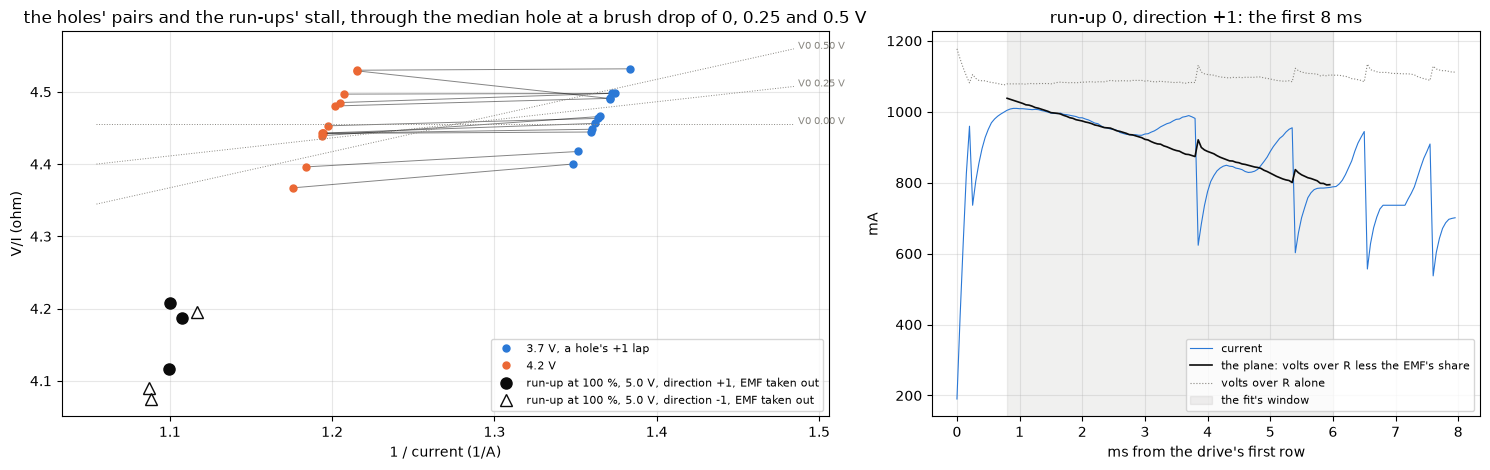

In [13]:
from scipy.optimize import curve_fit
ST = (Path("../../../telemetry") / f"{MOTOR.key}__{BOARD.key}" / "speed-torque" / "capture-1").resolve()   # the 100 % run-ups from rest at 5.0 V
st_cycles = pd.read_csv(ST / "cycles.csv")
RUN_WIN = (0.0008, 0.006)                 # s from the drive's first row: past the inductive rise, before the EMF is a fifth of the rail
RISE_WIN = (0.00005, 0.0006)              # the rise itself, for its time constant
rr, traces = [], {}
for _, C in st_cycles.iterrows():
    df, meta = tel.load(ST / C["folder"], BOARD)
    zero = float(tel.baseline(df)["current_raw"].median())
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        if int(g["cmd_duty_q15"].iloc[0]) == 0:
            continue                                                          # the coast after each run-up
        d = int(g["dir"].iloc[0])
        on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])
        g = g.iloc[on:]
        t = np.arange(len(g)) / FS
        i = (g["current_raw"].to_numpy(float) - zero - B_OFF) / G_CPA
        u = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - C_OFF) / K_CPV
        Q = np.cumsum(i) / FS                                                 # the charge passed so far, which the rotor's angle follows
        m = (t >= RUN_WIN[0]) & (t < RUN_WIN[1])
        b = np.linalg.lstsq(np.c_[u[m], Q[m]], i[m], rcond=None)[0]           # i = u / R - (Ke Kt / (J R)) Q
        R = 1 / b[0]
        J = -KE * KE / (b[1] * R)
        rise = (t >= RISE_WIN[0]) & (t < RISE_WIN[1])
        p, _ = curve_fit(lambda tt, I, tau, t0: I * (1 - np.exp(-(tt - t0) / tau)), t[rise], i[rise], p0=[1.0, 0.0002, 0.0])
        rr.append({"k": int(C["k"]), "dir": d, "r_app": R, "amps": i[m].mean(), "volts": u[m].mean(), "j": J, "tau_us": p[1] * 1e6,
                   "emf_end_v": KE * KE * Q[m][-1] / J, "fit_rms_ma": np.std(i[m] - np.c_[u[m], Q[m]] @ b) * 1e3})
        traces[(int(C["k"]), d)] = (t, i, u, b)
RUN = pd.DataFrame(rr)
R_RUN, R_RUN_SD, I_RUN = float(RUN["r_app"].mean()), float(RUN["r_app"].std()), float(RUN["amps"].mean())
I_TERM = float(HOLE["i_plus"].mean())
LEVER = 1 / I_TERM - 1 / I_RUN
V0_RUN = {"the holes' median": (R_TERM - R_RUN) / LEVER, "hole 0": (float(HOLE.loc[0, "r_plus"]) - R_RUN) / LEVER}
show(RUN.round(4), n=None)
print(f"the run-ups: R {R_RUN:.3f} ohm (sd {R_RUN_SD:.3f} over {len(RUN)}, direction +1 {RUN[RUN['dir'] == 1]['r_app'].mean():.3f}, -1 {RUN[RUN['dir'] == -1]['r_app'].mean():.3f}) "
      f"at {I_RUN:.2f} A on {RUN['volts'].mean():.2f} V; the rise's time constant {RUN['tau_us'].mean():.0f} us ({RUN['tau_us'].min():.0f} to {RUN['tau_us'].max():.0f}); "
      f"the EMF at 6 ms {RUN['emf_end_v'].mean():.2f} V; the plane leaves {RUN['fit_rms_ma'].mean():.0f} mA rms, the ripple")
print(f"the same fit's EMF term: J {RUN['j'].mean() * 1e9:.2f} x 1e-9 kg m^2 (sd {RUN['j'].std() * 1e9:.2f}), the drag left out, so a few percent high; "
      f"no-load-current's bracket is 4.4 to 8.2")
print(f"against the holes at {I_TERM:.2f} A, 1/I moves {LEVER:.3f} per A: a brush drop of " + ", ".join(f"{v:.2f} V from {k}" for k, v in V0_RUN.items())
      + f"; a 1 % difference in V/I between the two reads is {0.01 * R_TERM / LEVER:.2f} V of it")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a = ax[0]
for k in range(12):
    g = S[(S["hole"] == k) & (S["dir"] == 1)].set_index("level")
    x = 1 / g["i_start"]
    a.plot(x.loc[[3.7, 4.2]], g.loc[[3.7, 4.2], "r_start"], "-", lw=0.7, color=INK, alpha=0.5)
    a.plot(x.loc[3.7], g.loc[3.7, "r_start"], "o", ms=5, color=COLOR[3.7], label="3.7 V, a hole's +1 lap" if k == 0 else None)
    a.plot(x.loc[4.2], g.loc[4.2, "r_start"], "o", ms=5, color=COLOR[4.2], label="4.2 V" if k == 0 else None)
for d in (1, -1):
    h = RUN[RUN["dir"] == d]
    a.plot(1 / h["amps"], h["r_app"], MARK[d], ms=8, color=INK, mfc=INK if d == 1 else "none", label=f"run-up at 100 %, 5.0 V, direction {d:+d}, EMF taken out")
xx = np.array([1 / RUN["amps"].max() * 0.97, 1 / S["i_start"].min() * 1.02])
for v0 in (0.0, 0.25, 0.5):
    a.plot(xx, R_TERM - v0 / I_TERM + v0 * xx, color=MUTED, lw=0.7, ls=":")
    a.annotate(f"V0 {v0:.2f} V", (xx[1], R_TERM - v0 / I_TERM + v0 * xx[1]), fontsize=7, color=MUTED, xytext=(3, 0), textcoords="offset points")
a.set_xlabel("1 / current (1/A)"); a.set_ylabel("V/I (ohm)"); a.set_title("the holes' pairs and the run-ups' stall, through the median hole at a brush drop of 0, 0.25 and 0.5 V")
a.legend(fontsize=8); a.grid(alpha=0.3)
t, i, u, b = traces[(0, 1)]
m = (t >= RUN_WIN[0]) & (t < RUN_WIN[1])
ax[1].plot(t[t < 0.008] * 1e3, i[t < 0.008] * 1e3, lw=0.8, color=BLUE, label="current")
ax[1].plot(t[m] * 1e3, (np.c_[u[m], np.cumsum(i)[m] / FS] @ b) * 1e3, lw=1.2, color=INK, label="the plane: volts over R less the EMF's share")
ax[1].plot(t[t < 0.008] * 1e3, (u[t < 0.008] / RUN.iloc[0]["r_app"]) * 1e3, lw=0.8, ls=":", color=MUTED, label="volts over R alone")
ax[1].axvspan(RUN_WIN[0] * 1e3, RUN_WIN[1] * 1e3, color=MUTED, alpha=0.12, label="the fit's window")
ax[1].set_xlabel("ms from the drive's first row"); ax[1].set_ylabel("mA"); ax[1].set_title("run-up 0, direction +1: the first 8 ms"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

The run-ups read 4.15 ohm at 0.91 A, with a spread of 0.06 over the six and the directions 0.05 apart, the EMF taken out by the plane, which leaves the current's ripple and nothing else. The rise's time constant is about 190 us, so the window starts four of them in, and the EMF at the window's end is 1.2 V, a fifth of the rail. The same fit's EMF term gives an inertia of 6.0 x 10$^{-9}$ kg m$^2$ with a spread of 0.2, the drag left out so a few percent high, inside no-load-current's bracket and near its working value.

The 1 A points sit 7 % under the holes' pairs at 0.78 A. Read as a brush drop alone, through the median hole, that is 1.8 V, and 1.4 V through hole 0; the graded pairs, with a lever of 0.1 A, allow nothing near it, and the 3.3 V level does not either, since each 0.1 V of drop adds 0.3 % to a level that already sits under the chain's factor. So most of the 7 % is not the current level. Two candidates. The rotor turns from the first row, and the brushes slide over the segments through the window; a sliding contact reading under a locked one, or a brush crossing a segment gap and shorting a coil for part of each turn, which the locked holes never caught, would both put the free rotor's V/I under the locked one's. Possible, and nothing here tests it. Or the EMF taken out is too much: with the inertia at the top of no-load-current's bracket, 8.2, the EMF term is a quarter smaller and the run-ups read 4.25, which closes a third of the gap. Possible too. The run-ups say the drop is positive, since V/I falls with the current, and cannot say how large.

So the brush drop's bracket is 0 to 0.5 V, low confidence. The graded lines put it near zero and pull it low by the heat carried between levels, by up to a tenth or two of a volt; the run-ups say it is positive; and the 3.3 V level, which sits 1.5 % under what the chain's factor alone predicts, has room for about 0.5 V before a drop would push it past the couple of percent that factor is good to. Under a drop of 0.5 V the resistance the drop sits on is 3.8 ohm, and under none it is the 4.46 the holes read.

In [14]:
q = results.quantity
V0_LO, V0_HI = 0.0, 0.5          # the brush drop's bracket: the graded lines at the low end, the run-ups' lever at the high end


def rng(x, unit, value=None):
    # a value, the median unless given, with the range of x as the bounds
    x = pd.Series(x).dropna()
    return q(x.median() if value is None else value, x.min(), x.max(), unit)


v0p = SUM[(SUM["levels"] == "3.7 and 4.2 V") & (SUM["dir"] == 1)].iloc[0]
path = results.write("2-motor", "rest-resistance", CAPTURE, pair=MOTOR.key,
              notes=f"stall pass alone: 100 % laps of {S['lap_s'].max() * 1e3:.0f} ms into the rotor locked at twelve holes {DEG_PER_HOLE} degrees apart, "
                    f"rails {LEVELS} V, direction +1 then -1 a second later; current and terminal volts through the stage 1 current-scale and "
                    "terminal-chain results; each lap is read as V/I at the drive's first row, a line through V/I over "
                    f"{FIT_FROM_S * 1e3:.0f} ms to the end extrapolated back, so the lap's own warming and the early fall are out; "
                    "r_term_* is that V/I on the direction +1 laps at the graded levels (3.7 and 4.2 V), per hole the mean of the two, "
                    "the brush drop included, median over the holes with the range over the holes as the bounds; direction -1 starts warm "
                    "from the +1 lap and is reported apart; the 3.3 V level is not graded in stage 1 and enters no number; r_stall_ohm and "
                    "v0_brush_v are the brush drop and the resistance under it: the values are the line V = V0 + R I through each hole's two graded +1 laps at the start, "
                    "median over the holes (v0_graded_lines_v and r_stall_graded_lines_ohm carry those with their range), and the bounds are the bracket the "
                    "speed-torque run-ups' first milliseconds add, V0 from 0 to 0.5 V with R = r_term - V0 / I to match; r_runup_ohm is the run-ups' V/I at about "
                    "1 A with the EMF of the moving rotor taken out by a fit of the current on the volts and the charge, j_runup_kg_m2 the inertia that fit's EMF "
                    "term gives with the drag left out; hole_map_body_* is one warming body with a free time constant against the hole map, and "
                    "hole_map_angle_* what the map keeps once it is taken out; the copper's temperature is not measured, board_ntc_c is the board's",
              r_term_median_ohm=rng(HOLE["r_plus"], "ohm"),
              r_term_by_hole=[round(float(v), 4) for v in HOLE["r_plus"]],
              r_term_minus_by_hole=[round(float(v), 4) for v in HOLE["r_minus"]],
              r_term_angle_pct=rng(HOLE["map_pct"], "%", value=HOLE["map_pct"].max() - HOLE["map_pct"].min()),
              r_term_lap_scatter_pct=q(REPEAT_PCT, unit="%"),
              r_term_amps=rng(HOLE["i_plus"], "A", value=HOLE["i_plus"].mean()),
              r_stall_ohm=q(LINE_P["r"].median(), R_TERM - V0_HI / I_TERM, R_TERM, "ohm"),
              v0_brush_v=q(LINE_P["v0"].median(), V0_LO, V0_HI, "V"),
              r_stall_graded_lines_ohm=rng(LINE_P["r"], "ohm"),
              v0_graded_lines_v=rng(LINE_P["v0"], "V"),
              r_runup_ohm=q(R_RUN, R_RUN - R_RUN_SD, R_RUN + R_RUN_SD, "ohm"),
              r_runup_amps=q(I_RUN, RUN["amps"].min(), RUN["amps"].max(), "A"),
              v0_runup_lever_v=q(np.mean(list(V0_RUN.values())), min(V0_RUN.values()), max(V0_RUN.values()), "V"),
              j_runup_kg_m2=q(RUN["j"].mean(), RUN["j"].mean() - RUN["j"].std(), RUN["j"].mean() + RUN["j"].std(), "kg m^2"),
              runup_rise_tau_us=rng(RUN["tau_us"], "us", value=RUN["tau_us"].mean()),
              hole_map_body_tau_s=q(TAU_BODY, FITS[FITS["rms"] <= best["rms"] * 1.1]["tau"].min(), FITS[FITS["rms"] <= best["rms"] * 1.1]["tau"].max(), "s"),
              hole_map_body_share=q(HEAT_SHARE, unit=""),
              hole_map_body_span_pct=q(HOLE["heat_pct"].max() - HOLE["heat_pct"].min(), unit="%"),
              hole_map_angle_pct=rng(HOLE["angle_pct"], "%", value=HOLE["angle_pct"].std()),
              hole_map_angle_by_hole=[round(float(v), 3) for v in HOLE["angle_pct"]],
              v0_mean_v=q(v0p["v0_mean"], v0p["v0_mean"] - v0p["v0_se"], v0p["v0_mean"] + v0p["v0_se"], "V"),
              v0_all_rails_v=rng(VARIANTS["all three, 3.3 V as read"].query("dir == 1")["v0"], "V"),
              v0_all_rails_scaled_v=rng(VARIANTS["all three, 3.3 V scaled"].query("dir == 1")["v0"], "V"),
              r_stall_all_rails_ohm=rng(VARIANTS["all three, 3.3 V as read"].query("dir == 1")["r"], "ohm"),
              direction_gap_pct=rng(D["gap_pct"], "%", value=D["gap_pct"].mean()),
              direction_gap_kept=q(KEPT, KEPT - KEPT_SE, KEPT + KEPT_SE, ""),
              direction_gap_offset_ohm=q(ret["intercept"], ret["intercept"] - ret["intercept_se"], ret["intercept"] + ret["intercept_se"], "ohm"),
              copper_tau_s=q(TAU_S, -1 / np.log(KEPT - KEPT_SE), -1 / np.log(KEPT + KEPT_SE), "s"),
              warming_pct_per_j=rng(cold["pct_per_j"], "%/J", value=PCT_PER_J),
              copper_heat_capacity_max_j_per_c=q(C_MAX, unit="J/C"),
              copper_mass_max_g=q(C_MAX / C_CU, unit="g"),
              early_excess_pct=rng(S["early_pct"], "%", value=S["early_pct"].mean()),
              v_over_i_3v3_excess_pct=rng(EXCESS_3V3, "%"),
              v_over_i_3v3_stage1_pct=q((F_3V3 - 1) * 100, unit="%"),
              lap_joules=rng(S["joules"], "J", value=S["joules"].max()),
              board_ntc_c=rng(S["board_c"], "C"))
print("wrote", path)

wrote stages/2-motor/rest-resistance/results/mg90-b.json


## Limitations

- The copper's temperature is not measured. The laps are read at their start, so a lap's own warming is out, but the heat carried from the laps and holes before is in, and the Results suggest the carried part could be a percent or two between the first hole and the later ones. A degree of copper is 0.4 % of the copper's share of the reading. The board's NTC reads the board.
- The volts are the board's terminal taps at the connector, graded in stage 1 against the meter on a resistor to 0.7 counts, 3 mV, and the current is the current-scale line, graded to about 0.1 % on its slope. No meter reads the motor in this capture, so the result rests on those two grades, and the connector's contact and the motor's leads are in the reading.
- The 3.3 V level is not graded. VDD under the lap is not in the rows, and the stage 1 factor at that level comes from a resistor at a lower current.
- The brush drop is not resolved. Two graded levels 0.1 A apart leave each hole's line with about a tenth of a volt of spread, and the heat carried between levels moves the intercept by 27 mV per 0.1 % and is not measured. The run-ups' 1 A point is a free rotor's first milliseconds, read through a fit that takes the EMF out and with the brushes sliding over the segments from the first row, so it is a third current but not the same contact as a locked lap.
- Each hole is read once, in order, so the rotor's angle and the time through the pass are one axis. One warming body with a free time constant is the simplest split of the two, and its share of the map is as good as that model; how much of the map belongs to the angle stays open until the pass is run in another order.
- Twelve holes 30 degrees apart sample a 60 degree commutator pattern at two phases only, and the bar's holes are not the stops a free rotor picks when a drive ends. The spread at a servo's own stops may differ from the spread over the holes.
- The reading is at 0.69 to 0.85 A. A contact whose drop changes with the current reads differently at a milliamp or at two amps, and nothing here reaches either.

## What earlier work established

Before this stage the terminal resistance was read on MG90 motors inside their servos, with a meter across the terminals and with stall ladders on the board. Its data is not reused here, but its conclusions bear on what this notebook looks for.

- The reading belongs to the rotor's stop. With a meter at the stops a drive left, the bulk of the stops spread about 2 % from the lowest tenth to the median, and the worst stop read about 20 % over, skewed high. The twelve holes here spread 3.3 % from the lowest to the highest, with no hole far out, at an amp rather than a milliamp.
- The readings moved by 0.3 ohm between two sessions with the motor's first running, its orientation and the hands on the shaft all changed between them. That shift was never explained, and it is the reason the bar holds the pinion here and nothing presses along the shaft.
- A ratio of volts over amps at one current is not a resistance. On a locked ladder the ratio slid with the duty in a way a line through the same rungs reproduced as an intercept, and the intercepts of those lines landed anywhere from about -0.3 V to +0.5 V depending on the board and the rungs. This notebook reads the ratio at a known current and says so, and treats its own intercept the same way.
- A stall slope between small duties was dominated by the drive windows' own effects at a few microseconds of on time, so the laps here are at 100 % duty, where nothing switches.

## Open questions

- What the map over the holes belongs to, the angle or the time through the pass. A second pass over the same holes in the reverse order, with a fixed rest of two minutes between holes and a thermocouple on the can, splits them. A part that follows the hole is the angle, and a part that follows the order and the can's temperature is the heat. Re-clamping the bar 10 and 20 degrees round the pinion from its first seat, and reading the twelve holes again each time, samples the 60 degree pattern at six phases instead of two and finds any angle where a brush spans a gap.
- Why hole 0 reads low and differs in shape. It was the first hole of the pass and the coldest, and its laps lack the early fall. Reading hole 0 again at the end of the pass, after the motor has warmed like the others, tells the cold motor from the angle. A level that comes up to the other holes is the heat, and a reading that stays low and unsteady is the contact at that angle.
- What the second lap's gap is. Swapping the lap order at a few holes, direction -1 first, reads it again. Heat puts whichever direction runs second higher, and a polarity effect at the brushes stays with the direction. Swapping the motor's leads at the board's connector and running the usual order sorts the motor's current direction from the board's, since a contact effect follows the current through the brushes and a bridge effect follows the board. A rest of 20 s between the two directions removes the carried heat altogether.
- The brush drop. A locked lap at the USB levels is the clean third current, at 1.1 A on 5.0 V, and it reads against the run-ups' free-rotor 1 A whether the sliding contact reads under the locked one. A pass with the levels in reverse order, 4.2 V first, and 20 s of rest between levels, takes the carried heat out of the line or turns its sign. Adding the USB levels, 4.5 to 5.5 V, all graded, widens the current to about 1.1 A and the lever on $V_0$ almost three times, at 1 to 2 J per lap. The intercepts of those lines against this one's say how much of the present $V_0$ is heat.
- The early fall. The stage 1 resistor laps put it on the motor side, and what is not separated is the brush contact against the winding and its iron. The teardown's rotor, with leads on two commutator tabs and no brushes in the path, driven with the same 300 ms step from a supply and read on a scope across the tabs with a current probe, shows the winding's own response. A fall there belongs to the winding, and none there leaves the brushes. On the assembled motor, the same scope through the first 50 ms of a lap at a few holes, the first lap after a move against a later one, shows whether the fall follows the move.
- The slower warming at 3.3 V. A lap chunk that carries `vref_raw` beside the current channel gives VDD through the lap, which says whether the chain drifts within a 3.3 V lap. That is the stage 1 current-scale notebook's open question as well.

## Conclusion

The bare mg90-b motor's terminal resistance at rest reads 4.455 ohm in the median over twelve rotor angles 30 degrees apart, from 4.384 to 4.531 ohm, a spread of 3.3 % over the angle, at about 0.78 A on the board's own chains and with the brush drop in it. Each lap is read at its start, by a line through its $V/I$ extrapolated back over the warming, and the readings of one hole agree to 0.24 % between laps. The spread over the holes is real for this pass, and one warming body with a time constant of about 90 s explains 62 % of it, 2.1 % from the coldest hole to the warmest, so the warming between holes is not negligible: a hole's six laps leave a joule or two in a rotor-sized body that the next hole, a minute later, still carries a third of. What is left, -1.0 to +0.9 %, belongs to the angle, two and a half times the laps' own scatter, with no 60 or 120 degree pattern in it, the particular place each hole lands rather than the segments' geometry. Hole 0 keeps half its low reading after the heat is taken out.

The copper warms 1 to 3 % in a 300 ms lap at 2 to 3 W, a straight line at about 2.9 % per joule, which puts the copper's heat capacity at most at 0.14 J per C if every ohm is copper. Direction -1 starts 1.2 % higher than direction +1, and the gap is close to 59 % of the heat the first lap left, with a part from the direction itself under about 0.3 %. The copper gives its excess to the iron with a time constant of about 2 s.

The brush drop is not resolved. The per-hole lines through the graded levels give a slope of 4.40 ohm and an intercept of +0.06 V in the median, and the intercept spreads from -0.25 to +0.18 V over the holes, pulled low by the heat carried between levels at 27 mV per 0.1 %. The speed-torque run-ups add a third current, 4.15 ohm at 0.91 A with the EMF of the moving rotor fitted out, 7 % under the holes, which says the drop is positive and, read as a drop alone, far more than the graded pairs or the 3.3 V level allow, so most of that gap is the free rotor's sliding contact or the inertia the fit assumes, not the drop. The drop is between zero and 0.5 V, with low confidence, and the result carries that as its bounds.

Later stages take `r_term_median_ohm` as the terminal resistance at rest, with the brush drop included and the range over the angle as its bounds, and read it per hole from `r_term_by_hole`. The teardown subtracts the copper at this sitting's temperature from it to get what the brush path owns at an amp. For that it needs the copper's resistance at a known temperature, the copper's mass to check the warming bound, the rotor's mass for the heat carried between levels, and photos of the commutator and brushes to say how wide a segment gap is against 30 degrees. `r_stall_ohm` and `v0_brush_v` stand with the 0 to 0.5 V bracket as their bounds, and the next pass, with the levels reversed, the rests set and a locked lap at the USB levels, has to hold them before anything leans on the split between them.